# Model v2 - Deteksi Indikasi Pemalsuan Tanda Tangan (Siamese CNN)

Notebook ini mereproduksi **alur lengkap model v2** dari awal sampai evaluasi:

1. **Pengambilan data** - CEDAR + BHSig260 (Bengali + Hindi), termasuk pemeriksaan struktur folder.
2. **Pemrosesan data** - pengolahan citra `binary` yang sama dengan aplikasi, augmentasi "foto HP", cache gambar.
3. **Pembuatan pasangan** - pasangan asli-asli, tiruan mahir (*skilled forgery*), dan tiruan acak (*random forgery*).
4. **Pelatihan** - Siamese CNN dengan kontrasif loss, fokus menurunkan FAR tiruan mahir, pasangan diacak tiap epoch.
5. **Ensemble** - model lama + model hasil fine-tuning digabung menjadi satu model embedding.
6. **Kalibrasi** - batas keputusan dipilih di data validasi untuk target FAR tertentu, termasuk batas per jumlah pembanding (k = 1..5).
7. **Evaluasi** - AUC, EER, akurasi, FAR/FRR, confusion matrix, ROC, ketahanan foto HP, uji goyang, dan fusi ciri forensik.
8. **Simpan** - `embedding_model.keras`, `config.json`, tabel, grafik, dan ringkasan laporan.

**Data yang diharapkan** (struktur folder):

```
Dataset_Project/
├── CEDAR/CEDAR/                         (original_X_Y.png, forgeries_X_Y.png)
├── BHSig260-Bengali/BHSig260-Bengali/   (B-S-X-G-YY.tif, B-S-X-F-YY.tif)
└── BHSig260-Hindi/BHSig260-Hindi/       (H-S-X-G-YY.tif, H-S-X-F-YY.tif)
```

Opsional:
- `demo_model_files__6_/embedding_model.keras` untuk **fine-tuning** dan **ensemble** (model lama).
- `ttd_uji_sendiri/metadata.csv` + gambar untuk evaluasi **D3** (foto/scan sendiri).

**Cara pakai:** jalankan sel dari atas ke bawah. Di Colab pilih *Runtime -> Change runtime type -> T4 GPU*. Tanpa GPU, notebook otomatis membatasi epoch/pasangan agar tetap selesai.

## 0. (Opsional) Pasang Google Drive

Lewati jika dataset sudah ada di komputer atau sudah di-upload ke Colab.

In [1]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Bukan Colab / Drive tidak dipasang:", e)

Bukan Colab / Drive tidak dipasang: No module named 'google.colab'


## 1. Pengaturan

Semua parameter penting ada di sel ini. **Hanya bagian ini yang perlu diubah** kalau lokasi data berbeda.

In [2]:
# ===================== PENGATURAN =====================
import os, sys, json, math, random, hashlib, shutil, itertools, time, zipfile, traceback, re, importlib, warnings
from pathlib import Path

os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import cv2
import keras

try:
    import matplotlib.pyplot as plt
    ADA_MPL = True
except Exception:
    ADA_MPL = False

try:
    from IPython.display import display, Markdown
except Exception:
    display = print

SEED = 42
random.seed(SEED); np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

# ---------- lokasi data ----------
# None = dicari otomatis dari daftar di bawah. Isi manual bila perlu, contoh:
# JALUR_DATA = r"D:\Semester 5\Comvis\Dataset_Project"
JALUR_DATA = None
KANDIDAT_DATA = [
    r"D:\Semester 5\Comvis\Dataset_Project",
    "/content/drive/MyDrive/Dataset_Project",
    "/content/Dataset_Project",
    "/kaggle/input/dataset-project",
    str(Path.cwd() / "Dataset_Project"),
    str(Path.cwd()),
]
NAMA_DATASET = ("CEDAR", "BHSig260-Bengali", "BHSig260-Hindi")

# ---------- folder keluaran ----------
BASE_DIR  = Path.cwd()
OUT_DIR   = BASE_DIR / "hasil_model_v2"
CACHE_DIR = OUT_DIR / "cache"
MODEL_OUT = OUT_DIR / "model"
FIG_DIR   = OUT_DIR / "figures"
MODUL_DIR = BASE_DIR / "modules_v2"
for _d in (OUT_DIR, CACHE_DIR, MODEL_OUT, FIG_DIR, MODUL_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# ---------- model lama & foto sendiri (opsional) ----------
FOLDER_MODEL_LAMA = BASE_DIR / "demo_model_files__6_"
FOLDER_OWN        = BASE_DIR / "ttd_uji_sendiri"

# ---------- parameter v2 ----------
IMG_H, IMG_W = 128, 256
POS_PER_WRITER = {"CEDAR": 200, "BEN": 100, "HIN": 100}
FRAC_SKILLED   = 0.75     # porsi tiruan mahir di antara pasangan "beda"
W_SKILLED      = 1.5      # bobot loss untuk tiruan mahir
P_AUG_VARIAN   = 0.4      # peluang sisi pasangan memakai versi "foto HP"
MARGIN         = 1.0
BATCH_SIZE     = 64
EPOCHS         = 20
LEARNING_RATE  = 3e-4
PATIENCE       = 4
TARGET_FAR     = 0.08     # target FAR tiruan mahir di validasi (titik operasi aktif)
DAFTAR_TARGET  = (0.20, 0.10, 0.08, 0.05)
KS             = (1, 2, 3, 4, 5)
N_SHAKE        = 6
ABSTAIN_FRAC   = 0.20
TRIALS         = 20       # ulangan simulasi pembanding acak

# ---------- pilihan eksekusi ----------
MODE_CEPAT               = False   # True = data kecil + 2 epoch, untuk memastikan semua sel jalan
PAKAI_CACHE              = True    # pakai cache data.npz kalau sudah ada
TES_CEPAT                = True    # uji model 1 epoch sebelum training penuh
MULAI_DARI_MODEL_LAMA    = True    # False = latih dari nol (disarankan GPU)
BUAT_ENSEMBLE            = True    # gabung model lama + model baru seperti v2
JALANKAN_ANALISIS_TAMBAHAN = True  # ketahanan foto, uji goyang, fusi forensik

if MODE_CEPAT:
    EPOCHS = 2
    MAKS_PASANGAN_LATIH = 600
else:
    MAKS_PASANGAN_LATIH = None

print("TensorFlow:", __import__("tensorflow").__version__, "| Keras:", keras.__version__, "| backend:", keras.backend.backend())
print("Folder kerja :", BASE_DIR)
print("Folder data  :", JALUR_DATA or "(dicari otomatis)")
print("Folder output:", OUT_DIR)

TensorFlow: 2.22.0-rc0 | Keras: 3.15.1 | backend: tensorflow
Folder kerja : D:\Semester 5\Comvis\Project\pendeteksi-ttd
Folder data  : (dicari otomatis)
Folder output: D:\Semester 5\Comvis\Project\pendeteksi-ttd\hasil_model_v2


## 2. Pengambilan Data

Bagian ini mencari folder dataset, memeriksa kelengkapan, dan menampilkan statistiknya.
Jika dataset belum ada, unduh dulu:

- **CEDAR**: Kaggle `ishanikathuria/handwritten-signature-datasets`
- **BHSig260**: Kaggle `rajatkumar30/handwritten-signature-dataset` atau sumber resmi BHSig260.

Letakkan sesuai struktur pada judul notebook, lalu isi `JALUR_DATA` di sel pengaturan bila tidak terdeteksi otomatis.

In [3]:
def cari_subfolder(jalur, nama):
    """Cari folder dataset yang benar, baik berpola <root>/<nama>/<nama> maupun <root>/<nama>."""
    jalur = Path(jalur)
    for p in (jalur / nama / nama, jalur / nama):
        if p.is_dir():
            return p
    for p in jalur.rglob(nama):
        if p.is_dir():
            q = p / nama
            return q if q.is_dir() else p
    return None


def pilih_jalur_data():
    if JALUR_DATA:
        return Path(JALUR_DATA)
    for k in KANDIDAT_DATA:
        p = Path(k)
        if not p.exists():
            continue
        if all(cari_subfolder(p, n) is not None for n in NAMA_DATASET):
            return p
    return None


DATA_DIR = pilih_jalur_data()
if DATA_DIR is None:
    raise FileNotFoundError(
        "Dataset tidak ditemukan. Isi JALUR_DATA pada sel pengaturan dengan folder yang berisi "
        "CEDAR, BHSig260-Bengali, dan BHSig260-Hindi."
    )

FOLDERS = {n: cari_subfolder(DATA_DIR, n) for n in NAMA_DATASET}
print("Folder data :", DATA_DIR)
for n, p in FOLDERS.items():
    print(f"  {n:20s} -> {p}")

Folder data : D:\Semester 5\Comvis\Dataset_Project
  CEDAR                -> D:\Semester 5\Comvis\Dataset_Project\CEDAR\CEDAR
  BHSig260-Bengali     -> D:\Semester 5\Comvis\Dataset_Project\BHSig260-Bengali\BHSig260-Bengali
  BHSig260-Hindi       -> D:\Semester 5\Comvis\Dataset_Project\BHSig260-Hindi\BHSig260-Hindi


In [4]:
# Hitung jumlah file yang dikenali di setiap folder (belum membaca gambar)
POLA_CEK = {
    "CEDAR": re.compile(r"^(original|forgeries)_(\d+)_(\d+)\.(png|jpg)$", re.I),
    "BHSig260-Bengali": re.compile(r"^B-S-(\d+)-([GF])-(\d+)\.tif$", re.I),
    "BHSig260-Hindi": re.compile(r"^H-S-(\d+)-([GF])-(\d+)\.tif$", re.I),
}
for tag, root in FOLDERS.items():
    n = 0
    contoh = []
    for akar, _, files in os.walk(root):
        for f in files:
            if POLA_CEK[tag].match(f):
                n += 1
                if len(contoh) < 3:
                    contoh.append(os.path.relpath(os.path.join(akar, f), root))
    print(f"{tag:20s} : {n:6d} gambar cocok | contoh: {contoh}")

CEDAR                :   2640 gambar cocok | contoh: ['1\\forgeries_1_1.png', '1\\forgeries_1_10.png', '1\\forgeries_1_11.png']


BHSig260-Bengali     :   5400 gambar cocok | contoh: ['1\\B-S-1-F-01.tif', '1\\B-S-1-F-02.tif', '1\\B-S-1-F-03.tif']
BHSig260-Hindi       :   8640 gambar cocok | contoh: ['1\\H-S-1-F-01.tif', '1\\H-S-1-F-02.tif', '1\\H-S-1-F-03.tif']


## 3. Membaca Metadata dan Membagi Orang

Pembagian **per orang** 70% latih / 15% validasi / 15% uji, terpisah untuk setiap dataset (seed 42).
Orang di data latih tidak pernah muncul di validasi maupun uji.

Model v2 memakai **seluruh** BHSig260 (260 orang) yang sebelumnya terlewat karena nama file tidak dikenali notebook lama.

In [5]:
POLA = {
    "CEDAR": re.compile(r"^(original|forgeries)_(\d+)_(\d+)\.(png|jpg)$", re.I),
    "BEN":   re.compile(r"^B-S-(\d+)-([GF])-(\d+)\.tif$", re.I),
    "HIN":   re.compile(r"^H-S-(\d+)-([GF])-(\d+)\.tif$", re.I),
}
FOLDER_TAG = {"CEDAR": "CEDAR", "BEN": "BHSig260-Bengali", "HIN": "BHSig260-Hindi"}


def baca_meta(folders):
    baris = []
    for tag, rel in FOLDER_TAG.items():
        root = folders[rel]
        for akar, _, files in os.walk(root):
            for f in sorted(files):
                m = POLA[tag].match(f)
                if not m:
                    continue
                if tag == "CEDAR":
                    asli, w = m.group(1).lower() == "original", int(m.group(2))
                else:
                    asli, w = m.group(2).upper() == "G", int(m.group(1))
                baris.append({
                    "path": os.path.join(akar, f),
                    "dataset": tag,
                    "writer": f"{tag}_{w}",
                    "is_genuine": bool(asli),
                })
    return pd.DataFrame(baris)


def bagi_orang(meta, seed=SEED):
    from sklearn.model_selection import train_test_split
    peta = {}
    for tag in meta.dataset.unique():
        ws = sorted(meta[meta.dataset == tag].writer.unique())
        tr, tmp = train_test_split(ws, test_size=0.30, random_state=seed)
        va, te = train_test_split(tmp, test_size=0.50, random_state=seed)
        for w in tr: peta[w] = "train"
        for w in va: peta[w] = "val"
        for w in te: peta[w] = "test"
    return meta.writer.map(peta)


meta = baca_meta(FOLDERS)
if MODE_CEPAT:
    keep = []
    for tag in meta.dataset.unique():
        ws = sorted(meta[meta.dataset == tag].writer.unique())[:15]
        keep += ws
    meta = meta[meta.writer.isin(keep)].reset_index(drop=True)
    print("MODE_CEPAT: hanya memakai 15 orang pertama per dataset")

meta["split"] = bagi_orang(meta)
meta["aug"] = False
print("Gambar :", len(meta))
print("Orang  :", meta.writer.nunique())
print("\nOrang per dataset x split:")
print(meta.groupby(["dataset", "split"]).writer.nunique().unstack(fill_value=0))
print("\nGambar asli vs tiruan per dataset:")
print(meta.groupby(["dataset", "is_genuine"]).size().unstack(fill_value=0))

Gambar : 16680
Orang  : 315

Orang per dataset x split:
split    test  train  val
dataset                  
BEN        15     70   15
CEDAR       9     38    8
HIN        24    112   24

Gambar asli vs tiruan per dataset:
is_genuine  False  True 
dataset                 
BEN          3000   2400
CEDAR        1320   1320
HIN          4800   3840


## 4. Pengolahan Citra (file yang sama dengan aplikasi)

Tiga modul ditulis ke folder `modules_v2/` lalu diimpor. Isinya **identik** dengan
`demo_model_files_v2/preprocess.py`, `forensik.py`, dan `gangguan.py`, supaya hasil notebook dan aplikasi selalu sama.

- `preprocess.py` - ratakan cahaya, pisahkan tinta dengan Otsu, buang bintik, crop, dan seragamkan ke 128 x 256.
- `forensik.py` - 8 ciri klasik (bentuk, kepadatan tinta, kemiringan, ketebalan, jumlah bagian, panjang goresan, posisi).
- `gangguan.py` - bayangan, buram, miring, redup, noise, kompresi, dan gabungan "foto HP".

In [6]:
%%writefile modules_v2/preprocess.py
"""
preprocess.py - pengolahan citra tanda tangan.

File ini dipakai di DUA tempat supaya hasilnya selalu sama:
  1. notebook training (Google Colab)
  2. aplikasi demo (folder demo/)

Aturan keluaran: gambar ukuran (out_h, out_w), nilai 0..1,
  - latar belakang = 0 (hitam)
  - goresan tanda tangan = mendekati 1 (terang)
"""

import cv2
import numpy as np
from PIL import Image

IMG_H = 128
IMG_W = 256

# raw    : hanya grayscale + resize (cara awal, dipakai sebagai pembanding)
# gray   : koreksi cahaya + buang bintik + crop + resize, tinta tetap abu-abu
# binary : sama seperti gray, tetapi tinta dijadikan hitam-putih murni (Otsu)
MODES = ("raw", "gray", "binary")


def load_gray(source):
    """Baca gambar dari path / file-like object menjadi array uint8 2D (0=hitam, 255=putih)."""
    img = Image.open(source)
    if img.mode in ("RGBA", "LA") or (img.mode == "P" and "transparency" in img.info):
        img = img.convert("RGBA")
        latar = Image.new("RGBA", img.size, (255, 255, 255, 255))
        latar.alpha_composite(img)
        img = latar
    return np.array(img.convert("L"), dtype=np.uint8)


def _fit_to_canvas(img, out_h, out_w):
    """Perkecil/perbesar tanpa merusak rasio, lalu taruh di tengah kanvas hitam."""
    h, w = img.shape
    skala = min(out_h / h, out_w / w)
    new_w = max(1, int(round(w * skala)))
    new_h = max(1, int(round(h * skala)))
    kecil = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)
    kanvas = np.zeros((out_h, out_w), dtype=np.uint8)
    y0 = (out_h - new_h) // 2
    x0 = (out_w - new_w) // 2
    kanvas[y0:y0 + new_h, x0:x0 + new_w] = kecil
    return kanvas


def _limit_size(gray, max_side=1600):
    """Foto kamera bisa sangat besar; kecilkan dulu supaya proses cepat."""
    h, w = gray.shape
    if max(h, w) <= max_side:
        return gray
    s = max_side / max(h, w)
    return cv2.resize(gray, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)


def _flatten_lighting(gray):
    """Ratakan cahaya (bayangan / kertas tidak rata) dengan membagi gambar dengan latarnya."""
    h, w = gray.shape
    f = max(1, max(h, w) // 400)          # hitung latar pada gambar kecil supaya cepat
    kecil = cv2.resize(gray, (max(1, w // f), max(1, h // f)), interpolation=cv2.INTER_AREA)
    sigma = max(kecil.shape) / 20.0
    latar = cv2.GaussianBlur(kecil, (0, 0), sigmaX=sigma)
    latar = cv2.resize(latar, (w, h), interpolation=cv2.INTER_LINEAR)
    latar = np.maximum(latar, 1)
    return cv2.divide(gray, latar, scale=255)


def _remove_specks(mask, min_area=10):
    """Buang bintik kecil (debu hasil scan). Versi cepat tanpa perulangan per bintik."""
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    simpan = stats[:, cv2.CC_STAT_AREA] >= min_area
    simpan[0] = False                      # label 0 = latar
    return (simpan[labels].astype(np.uint8)) * 255


def _core(gray):
    """Langkah bersama untuk mode gray dan binary: ratakan cahaya, pisahkan tinta (Otsu), buang bintik."""
    gray = _limit_size(np.asarray(gray, dtype=np.uint8))
    rata = _flatten_lighting(gray)
    halus = cv2.GaussianBlur(rata, (3, 3), 0)
    _, mask = cv2.threshold(halus, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    mask = _remove_specks(mask)
    return rata, mask


def _crop(tinta, mask):
    ys, xs = np.where(mask > 0)
    h, w = tinta.shape
    margin = max(2, int(0.03 * max(h, w)))
    y1, y2 = max(0, ys.min() - margin), min(h, ys.max() + margin + 1)
    x1, x2 = max(0, xs.min() - margin), min(w, xs.max() + margin + 1)
    return tinta[y1:y2, x1:x2]


def _raw(gray, out_h, out_w):
    terbalik = 255 - np.asarray(gray, dtype=np.uint8)
    hasil = cv2.resize(terbalik, (out_w, out_h), interpolation=cv2.INTER_AREA)
    return hasil.astype(np.float32) / 255.0


def preprocess_signature(gray, mode="binary", out_h=IMG_H, out_w=IMG_W, return_steps=False):
    """
    gray : array uint8 2D (0=hitam ... 255=putih)
    return: array float32 (out_h, out_w) 0..1  (atau (hasil, dict langkah) bila return_steps=True)
    """
    if mode not in MODES:
        raise ValueError(f"mode harus salah satu dari {MODES}")

    gray = np.asarray(gray, dtype=np.uint8)
    steps = {"asli": gray}

    if mode == "raw":
        hasil = _raw(gray, out_h, out_w)
        steps["hasil"] = hasil
        return (hasil, steps) if return_steps else hasil

    rata, mask = _core(gray)
    steps["cahaya_rata"] = rata
    steps["mask"] = mask

    if not mask.any():
        hasil = np.zeros((out_h, out_w), dtype=np.float32)
        steps["hasil"] = hasil
        return (hasil, steps) if return_steps else hasil

    tinta = mask if mode == "binary" else np.where(mask > 0, 255 - rata, 0).astype(np.uint8)
    potong = _crop(tinta, mask)
    steps["potong"] = potong
    if mode == "gray":                      # untuk ciri forensik selalu sediakan potongan hitam-putih
        steps["potong_biner"] = _crop(mask, mask)
    hasil = _fit_to_canvas(potong, out_h, out_w).astype(np.float32) / 255.0
    steps["hasil"] = hasil
    return (hasil, steps) if return_steps else hasil


def preprocess_all(gray, modes=MODES, out_h=IMG_H, out_w=IMG_W):
    """
    Olah satu gambar untuk beberapa mode sekaligus (lebih cepat dari memanggil satu-satu).
    return: (dict mode -> array float32, potongan_biner uint8 atau None)
    potongan_biner dipakai untuk menghitung ciri forensik.
    """
    gray = np.asarray(gray, dtype=np.uint8)
    hasil, potong_biner = {}, None
    if "raw" in modes:
        hasil["raw"] = _raw(gray, out_h, out_w)
    perlu_inti = any(m in modes for m in ("gray", "binary"))
    if perlu_inti:
        rata, mask = _core(gray)
        if not mask.any():
            for m in ("gray", "binary"):
                if m in modes:
                    hasil[m] = np.zeros((out_h, out_w), dtype=np.float32)
        else:
            potong_biner = _crop(mask, mask)
            if "binary" in modes:
                hasil["binary"] = _fit_to_canvas(potong_biner, out_h, out_w).astype(np.float32) / 255.0
            if "gray" in modes:
                tinta = np.where(mask > 0, 255 - rata, 0).astype(np.uint8)
                hasil["gray"] = _fit_to_canvas(_crop(tinta, mask), out_h, out_w).astype(np.float32) / 255.0
    return hasil, potong_biner

Overwriting modules_v2/preprocess.py


In [7]:
%%writefile modules_v2/forensik.py
"""
forensik.py - ciri tanda tangan yang dihitung dengan pengolahan citra klasik (tanpa deep learning).

Ciri ini dipakai untuk dua hal:
  1. Laporan forensik mini: menjelaskan KENAPA dua tanda tangan dianggap mirip / beda.
  2. Digabung dengan jarak dari model Siamese (fusi), lalu diuji apakah error turun.
"""

import cv2
import numpy as np

try:
    from skimage.morphology import skeletonize as _skeletonize
except Exception:  # noqa: BLE001
    _skeletonize = None

NAMA_CIRI = [
    "rasio_lebar_tinggi",
    "kepadatan_tinta",
    "kemiringan",
    "ketebalan_goresan",
    "jumlah_bagian",
    "panjang_goresan",
    "posisi_x",
    "posisi_y",
]

LABEL_CIRI = {
    "rasio_lebar_tinggi": "Bentuk (lebar dibanding tinggi)",
    "kepadatan_tinta": "Kepadatan tinta",
    "kemiringan": "Kemiringan umum",
    "ketebalan_goresan": "Ketebalan goresan",
    "jumlah_bagian": "Jumlah bagian terpisah (angkat pena)",
    "panjang_goresan": "Panjang total goresan",
    "posisi_x": "Letak pusat tinta (kiri-kanan)",
    "posisi_y": "Letak pusat tinta (atas-bawah)",
}

# ciri yang dibandingkan dengan rasio (log) vs selisih biasa
_LOG = {"rasio_lebar_tinggi", "kepadatan_tinta", "ketebalan_goresan", "jumlah_bagian", "panjang_goresan"}


def extract_features(potong):
    """potong: array uint8 hasil crop mask tinta (0/255). return: vektor float32 panjang 8, atau None."""
    if potong is None or potong.size == 0 or not potong.any():
        return None
    h0, w0 = potong.shape
    s = 96.0 / h0
    m = cv2.resize(potong, (max(8, int(round(w0 * s))), 96), interpolation=cv2.INTER_AREA) > 64
    ys, xs = np.nonzero(m)
    if len(ys) < 5:
        return None
    luas = float(m.sum())
    rasio = w0 / h0
    kepadatan = luas / m.size

    mu20, mu02 = float(np.var(xs)), float(np.var(ys))
    mu11 = float(np.mean((xs - xs.mean()) * (ys - ys.mean())))
    miring = float(np.degrees(0.5 * np.arctan2(2 * mu11, mu20 - mu02 + 1e-9)))

    if _skeletonize is not None:
        rangka = _skeletonize(m)
        panjang = float(rangka.sum())
    else:
        panjang = luas / 3.0
    tebal = luas / max(panjang, 1.0)
    n_bagian = float(cv2.connectedComponents(m.astype(np.uint8), connectivity=8)[0] - 1)
    panjang_norm = panjang / float(np.hypot(*m.shape))
    cx, cy = float(xs.mean() / m.shape[1]), float(ys.mean() / m.shape[0])
    return np.array([rasio, kepadatan, miring, tebal, n_bagian, panjang_norm, cx, cy], dtype=np.float32)


def feature_diffs(v1, v2):
    """Selisih per ciri antara dua tanda tangan (selalu >= 0). Dipakai untuk fusi dan untuk laporan."""
    out = np.zeros(len(NAMA_CIRI), dtype=np.float32)
    for i, nama in enumerate(NAMA_CIRI):
        a, b = float(v1[i]), float(v2[i])
        if nama in _LOG:
            out[i] = abs(np.log((a + 1e-3) / (b + 1e-3)))
        elif nama == "kemiringan":
            d = abs(a - b)
            out[i] = min(d, 180.0 - d)
        else:
            out[i] = abs(a - b)
    return out


def _fmt(nama, v):
    if nama == "kemiringan":
        return f"{v:.0f} derajat"
    if nama == "jumlah_bagian":
        return f"{v:.0f} bagian"
    if nama in ("posisi_x", "posisi_y"):
        return f"{v * 100:.0f}%"
    if nama == "kepadatan_tinta":
        return f"{v * 100:.1f}%"
    return f"{v:.2f}"


def explain(v_ref, v_qry, batas):
    """
    Laporan forensik mini.
    batas: dict nama_ciri -> [p75, p95] dari selisih pada pasangan tanda tangan ASLI (dihitung di notebook).
    return: list dict {ciri, label, pembanding, diperiksa, tingkat, kalimat}
    """
    d = feature_diffs(v_ref, v_qry)
    hasil = []
    for i, nama in enumerate(NAMA_CIRI):
        p75, p95 = batas[nama]
        if d[i] <= p75:
            tingkat = "mirip"
        elif d[i] <= p95:
            tingkat = "agak beda"
        else:
            tingkat = "beda"
        a, b = _fmt(nama, v_ref[i]), _fmt(nama, v_qry[i])
        hasil.append({
            "ciri": nama,
            "label": LABEL_CIRI[nama],
            "pembanding": a,
            "diperiksa": b,
            "tingkat": tingkat,
            "kalimat": f"{LABEL_CIRI[nama]}: pembanding {a}, diperiksa {b} ({tingkat}).",
            "selisih": float(d[i]),
        })
    return hasil

Overwriting modules_v2/forensik.py


In [8]:
%%writefile modules_v2/gangguan.py
"""
gangguan.py - gangguan buatan pada gambar tanda tangan.

Dua kegunaan:
  1. Meniru kondisi foto dari HP (bayangan, buram, miring, redup, noise, kompresi JPEG)
     untuk menguji ketahanan model.
  2. "Uji goyang": membuat beberapa versi sedikit bergeser/berputar dari satu gambar
     untuk mengukur seberapa stabil keputusan model.
"""

import cv2
import numpy as np


def bayangan(gray, rng):
    h, w = gray.shape
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
    sudut = rng.uniform(0, 2 * np.pi)
    proj = (xx / w - 0.5) * np.cos(sudut) + (yy / h - 0.5) * np.sin(sudut)
    sig = 1.0 / (1.0 + np.exp(-proj * rng.uniform(4, 9)))
    kuat = rng.uniform(0.35, 0.6)
    faktor = 1.0 - kuat * sig
    return np.clip(gray.astype(np.float32) * faktor, 0, 255).astype(np.uint8)


def buram(gray, rng):
    sigma = rng.uniform(1.0, 2.2) * max(gray.shape) / 300.0
    return cv2.GaussianBlur(gray, (0, 0), sigmaX=max(sigma, 0.8))


def miring(gray, rng):
    h, w = gray.shape
    sudut = rng.uniform(4, 9) * rng.choice([-1, 1])
    M = cv2.getRotationMatrix2D((w / 2, h / 2), sudut, 1.0)
    return cv2.warpAffine(gray, M, (w, h), flags=cv2.INTER_LINEAR, borderValue=255)


def redup(gray, rng):
    alpha = rng.uniform(0.45, 0.65)     # kontras turun
    beta = rng.uniform(0, 25)
    return np.clip(gray.astype(np.float32) * alpha + beta, 0, 255).astype(np.uint8)


def derau(gray, rng):
    n = rng.normal(0, rng.uniform(10, 20), gray.shape)
    return np.clip(gray.astype(np.float32) + n, 0, 255).astype(np.uint8)


def kompresi(gray, rng):
    ok, buf = cv2.imencode(".jpg", gray, [cv2.IMWRITE_JPEG_QUALITY, int(rng.integers(15, 35))])
    return cv2.imdecode(buf, cv2.IMREAD_GRAYSCALE)


def foto_hp(gray, rng):
    """Gabungan: agak miring + bayangan + sedikit buram + noise + kompresi (mirip foto kertas dari HP)."""
    g = miring(gray, rng)
    g = bayangan(g, rng)
    g = cv2.GaussianBlur(g, (0, 0), sigmaX=max(0.8, 0.7 * max(g.shape) / 300.0))
    g = derau(g, rng)
    return kompresi(g, rng)


KONDISI = {
    "bayangan": bayangan,
    "buram": buram,
    "miring": miring,
    "redup": redup,
    "noise": derau,
    "foto_hp": foto_hp,
}


def shake_variants(arr, n=10, seed=0, max_shift=0.04, max_rot=3.0, max_scale=0.05):
    """
    arr: array float32 (H, W) hasil pengolahan citra (0..1, latar 0).
    return: array (n, H, W, 1). Setiap versi digeser, diputar, dan diperbesar/diperkecil sedikit.
    """
    rng = np.random.default_rng(seed)
    h, w = arr.shape
    out = np.empty((n, h, w, 1), dtype=np.float32)
    for i in range(n):
        sudut = rng.uniform(-max_rot, max_rot)
        skala = 1.0 + rng.uniform(-max_scale, max_scale)
        M = cv2.getRotationMatrix2D((w / 2, h / 2), sudut, skala)
        M[0, 2] += rng.uniform(-max_shift, max_shift) * w
        M[1, 2] += rng.uniform(-max_shift, max_shift) * h
        out[i, :, :, 0] = cv2.warpAffine(arr, M, (w, h), flags=cv2.INTER_LINEAR, borderValue=0)
    return out

Overwriting modules_v2/gangguan.py


In [9]:
sys.path.insert(0, str(MODUL_DIR))
import preprocess, forensik, gangguan
for _m in (preprocess, forensik, gangguan):
    importlib.reload(_m)

from preprocess import IMG_H, IMG_W, load_gray, preprocess_signature, preprocess_all
from forensik import NAMA_CIRI, extract_features, feature_diffs, explain
from gangguan import KONDISI, shake_variants

print("Modul siap. Ukuran input:", (IMG_H, IMG_W), "| ciri forensik:", len(NAMA_CIRI))

Modul siap. Ukuran input: (128, 256) | ciri forensik: 8


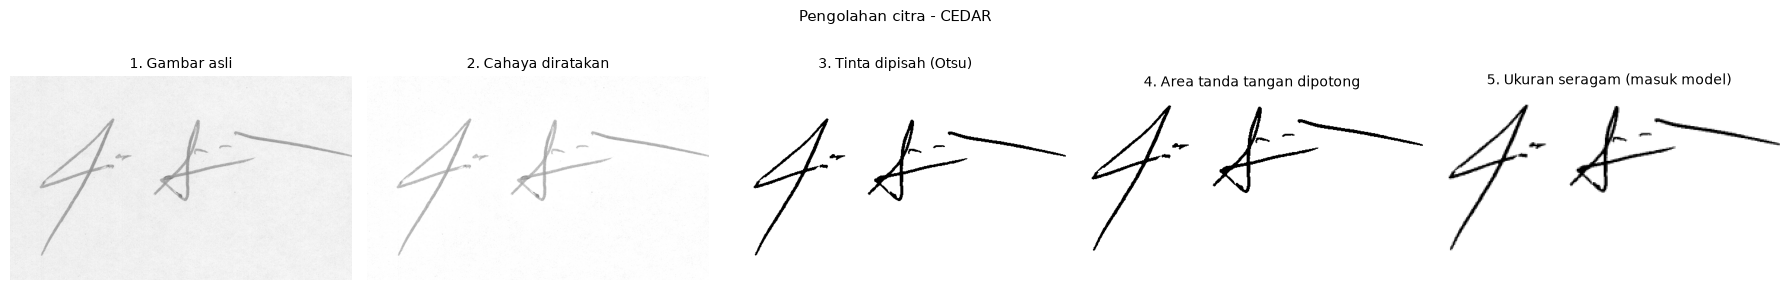

In [10]:
# Contoh tahapan pengolahan citra untuk satu tanda tangan asli dari tiap dataset
def contoh_langkah(path, judul):
    gray0 = load_gray(path)
    _, langkah = preprocess_signature(gray0, "binary", return_steps=True)
    panel = [
        ("1. Gambar asli", langkah["asli"]),
        ("2. Cahaya diratakan", langkah["cahaya_rata"]),
        ("3. Tinta dipisah (Otsu)", 255 - langkah["mask"]),
        ("4. Area tanda tangan dipotong", 255 - langkah["potong"]),
        ("5. Ukuran seragam (masuk model)", 1 - langkah["hasil"]),
    ]
    fig, axes = plt.subplots(1, len(panel), figsize=(18, 3.2))
    for ax, (jd, im) in zip(axes, panel):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255 if im.dtype == np.uint8 else 1)
        ax.set_title(jd, fontsize=10); ax.axis("off")
    fig.suptitle(judul, fontsize=11)
    plt.tight_layout(); plt.show()

if ADA_MPL:
    for tag, root in FOLDERS.items():
        calon = meta[(meta.dataset == tag) & meta.is_genuine]
        if len(calon):
            contoh_langkah(calon.iloc[0].path, f"Pengolahan citra - {tag}")
else:
    print("matplotlib tidak terpasang -> contoh gambar dilewati")

## 5. Memproses Semua Gambar + Cache

Semua gambar (termasuk versi augmentasi "foto HP" untuk orang latih) diolah **sekali** dengan mode `binary`,
lalu disimpan ke `hasil_model_v2/cache/data.npz` (gambar uint8) dan `meta.csv`.

- Tambahan versi "foto HP" hanya untuk orang **latih** (bayangan/buram/miring/redup/noise).
- Proses ± 28.000 gambar (data penuh + augmentasi), sekitar 0,9 GB di RAM/disk.
- Kalau cache sudah ada dan `PAKAI_CACHE = True`, sel ini langsung memuat cache.

In [11]:
cache_npz  = CACHE_DIR / "data.npz"
cache_meta = CACHE_DIR / "meta.csv"

if PAKAI_CACHE and cache_npz.exists() and cache_meta.exists():
    print("Memuat cache:", cache_npz)
    _d = np.load(cache_npz)
    img = _d["img"]
    feat = _d["feat"]
    meta_all = pd.read_csv(cache_meta, encoding="utf-8")
    meta_all["aug"] = meta_all["aug"].astype(bool)
    meta_all["is_genuine"] = meta_all["is_genuine"].astype(bool)
    print("Cache dimuat:", img.shape, feat.shape, "| meta:", meta_all.shape)
else:
    # Bangun daftar gambar: data dasar + salinan "foto HP" untuk orang latih
    tr_aug = meta[meta.split == "train"].copy()
    tr_aug["aug"] = True
    semua = pd.concat([meta, tr_aug], ignore_index=True)

    def olah_satu(args):
        path, aug, seed = args
        try:
            g = load_gray(path)
            if aug:
                rng = np.random.default_rng(seed)
                nama = list(KONDISI)
                g = KONDISI[nama[int(rng.integers(len(nama)))]](g, rng)
            arrs, potong = preprocess_all(g, ("binary",))
            fitur = extract_features(potong)
            if fitur is None:
                return None
            return (arrs["binary"] * 255).astype(np.uint8), fitur
        except Exception:
            return None

    tugas = [(p, bool(au), SEED + i) for i, (p, au) in enumerate(zip(semua.path, semua.aug))]
    from tqdm.auto import tqdm
    from concurrent.futures import ThreadPoolExecutor

    t0 = time.time()
    with ThreadPoolExecutor(max_workers=max(2, (os.cpu_count() or 4) - 1)) as ex:
        hasil = list(tqdm(ex.map(olah_satu, tugas), total=len(tugas), desc="mengolah gambar"))

    ok = np.array([h is not None for h in hasil])
    print(f"Berhasil {int(ok.sum())} dari {len(hasil)} | {time.time() - t0:.0f} detik")
    semua = semua[ok].reset_index(drop=True)
    img = np.stack([h[0] for h in hasil if h is not None])
    feat = np.stack([h[1] for h in hasil if h is not None]).astype(np.float32)
    np.savez(cache_npz, img=img, feat=feat)
    semua.to_csv(cache_meta, index=False)
    meta_all = semua
    del hasil
    print("Cache tersimpan:", img.shape, feat.shape, "| meta:", meta_all.shape)

mengolah gambar:   0%|          | 0/28332 [00:00<?, ?it/s]

Berhasil 28332 dari 28332 | 2683 detik


Cache tersimpan: (28332, 128, 256) (28332, 8) | meta: (28332, 6)


## 6. Membuat Pasangan Gambar

Label pasangan: **0 = mirip** (asli vs asli orang yang sama), **1 = beda**.
Pasangan "beda" terdiri dari:

- **Tiruan mahir** (*skilled forgery*): asli vs tiruan orang yang sama. Porsi 75% dan bobot loss 1,5 (fokus v2).
- **Tiruan acak** (*random forgery*): asli vs asli orang lain di dataset yang sama.

Pasangan diacak ulang setiap epoch saat training, sehingga model melihat kombinasi yang jauh lebih banyak.

In [12]:
TIPE = {0: "genuine_pair", 1: "skilled_forgery", 2: "random_forgery"}


def buat_pasangan(meta, split, n_pos, seed, pakai_aug=False, datasets=None):
    """meta: DataFrame dengan index = baris cache gambar. Kolom: path, dataset, writer, is_genuine, split, aug."""
    rng = random.Random(seed)
    base = meta[(meta.split == split) & (~meta.aug)]
    if datasets is not None:
        base = base[base.dataset.isin(datasets)]
    aug_idx = {}
    if pakai_aug:
        for i, p in zip(meta.index[meta.aug], meta.path[meta.aug]):
            aug_idx[p] = i
    ws = sorted(base.writer.unique())
    gen = {w: base.index[(base.writer == w) & base.is_genuine].tolist() for w in ws}
    frg = {w: base.index[(base.writer == w) & ~base.is_genuine].tolist() for w in ws}
    ws = [w for w in ws if len(gen[w]) >= 2]
    ds = base.groupby("writer").dataset.first().to_dict()
    path = meta.path.to_dict()
    rows = []

    def varian(i):
        if pakai_aug and rng.random() < P_AUG_VARIAN:
            return aug_idx.get(path[i], i)
        return i

    def add(a, b, y, t, d):
        if rng.random() < 0.5:
            a, b = b, a
        rows.append((varian(a), varian(b), y, t, d))

    for w in ws:
        g, f = gen[w], frg[w]
        if len(g) < 2:
            continue
        n = n_pos[ds[w]] if isinstance(n_pos, dict) else n_pos
        semua = [(a, b) for ia, a in enumerate(g) for b in g[ia + 1:]]
        pos = rng.sample(semua, min(n, len(semua)))
        for a, b in pos:
            add(a, b, 0, 0, ds[w])
        n_skl = int(round(len(pos) * FRAC_SKILLED)) if f else 0
        if f:
            kombinasi = [(a, b) for a in g for b in f]
            for a, b in rng.sample(kombinasi, min(n_skl, len(kombinasi))):
                add(a, b, 1, 1, ds[w])
        lain = [x for x in ws if x != w and ds[x] == ds[w]]
        for _ in range(len(pos) - n_skl):
            o = rng.choice(lain)
            add(rng.choice(g), rng.choice(gen[o]), 1, 2, ds[w])
    df = pd.DataFrame(rows, columns=["i1", "i2", "label", "tipe", "dataset"])
    return df.sample(frac=1, random_state=seed).reset_index(drop=True)


PAIRS = {
    "train": buat_pasangan(meta_all, "train", POS_PER_WRITER, SEED, pakai_aug=True),
    "val":   buat_pasangan(meta_all, "val", 60, SEED + 1),
    "test":  buat_pasangan(meta_all, "test", 100, SEED + 2),
}
for nama, p in PAIRS.items():
    print(f"{nama:5s} total {len(p):6d} | mirip {int((p.label == 0).sum()):5d} | beda {int((p.label == 1).sum()):5d} | "
          f"{ {TIPE[k]: int(v) for k, v in p.tipe.value_counts().items()} }")

train total  51400 | mirip 25700 | beda 25700 | {'genuine_pair': 25700, 'skilled_forgery': 19275, 'random_forgery': 6425}
val   total   5640 | mirip  2820 | beda  2820 | {'genuine_pair': 2820, 'skilled_forgery': 2115, 'random_forgery': 705}
test  total   9600 | mirip  4800 | beda  4800 | {'genuine_pair': 4800, 'skilled_forgery': 3600, 'random_forgery': 1200}


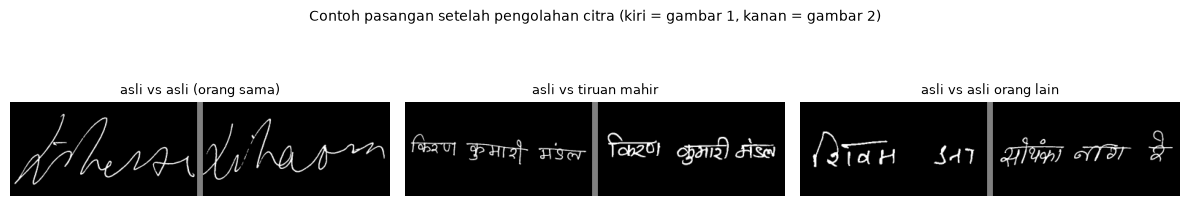

In [13]:
# Contoh pasangan dari data uji
if ADA_MPL:
    p = PAIRS["test"]
    contoh = [
        ("asli vs asli (orang sama)", p[p.tipe == 0].iloc[0]),
        ("asli vs tiruan mahir", p[p.tipe == 1].iloc[0]),
        ("asli vs asli orang lain", p[p.tipe == 2].iloc[0]),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(12, 2.6))
    for ax, (jd, r) in zip(axes, contoh):
        a = img[int(r.i1)]; b = img[int(r.i2)]
        gab = np.concatenate([a, np.full((a.shape[0], 8), 128, np.uint8), b], axis=1)
        ax.imshow(gab, cmap="gray", vmin=0, vmax=255)
        ax.set_title(jd, fontsize=9); ax.axis("off")
    plt.suptitle("Contoh pasangan setelah pengolahan citra (kiri = gambar 1, kanan = gambar 2)", fontsize=10)
    plt.tight_layout(); plt.show()

## 7. Model Siamese CNN

Arsitektur **sama persis** dengan model lama/v2: 4 blok Conv-BatchNorm-ReLU-MaxPool (32/64/128/256),
flatten, dropout 0,4, dense 128, embedding 64, lalu L2-normalization.

Dua gambar masuk ke jaringan yang sama, lalu dihitung jarak Euclidean. Loss kontrasif:
mirip -> jarak ditekan ke 0, beda -> jarak didorong melebihi margin 1,0.
Pasangan tiruan mahir diberi bobot loss 1,5.

In [14]:
from keras import ops


def build_embedding_net(embedding_dim=64):
    inp = keras.Input(shape=(IMG_H, IMG_W, 1), name="signature")
    x = inp
    for filters in (32, 64, 128, 256):
        x = keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = keras.layers.BatchNormalization()(x)
        x = keras.layers.Activation("relu")(x)
        x = keras.layers.MaxPooling2D(2)(x)
    x = keras.layers.Flatten()(x)
    x = keras.layers.Dropout(0.4)(x)
    x = keras.layers.Dense(128, activation="relu")(x)
    x = keras.layers.Dense(embedding_dim)(x)
    x = keras.layers.UnitNormalization(name="l2_norm")(x)
    return keras.Model(inp, x, name="embedding_net")


def bangun_siamese(base):
    a = keras.Input(shape=(IMG_H, IMG_W, 1), name="image1")
    b = keras.Input(shape=(IMG_H, IMG_W, 1), name="image2")
    ea, eb = base(a), base(b)
    d = keras.layers.Lambda(
        lambda t: ops.sqrt(ops.sum(ops.square(t[0] - t[1]), axis=1, keepdims=True) + 1e-9),
        output_shape=(1,), name="jarak")([ea, eb])
    return keras.Model([a, b], d, name="siamese")


def augment(img2d, rng):
    h, w = img2d.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), rng.uniform(-3, 3), 1.0 + rng.uniform(-0.05, 0.05))
    M[0, 2] += rng.uniform(-0.04, 0.04) * w
    M[1, 2] += rng.uniform(-0.04, 0.04) * h
    return cv2.warpAffine(img2d, M, (w, h), flags=cv2.INTER_LINEAR, borderValue=0)


class Pasangan(keras.utils.PyDataset):
    def __init__(self, img, meta, split, n_pos, seed, batch=BATCH_SIZE, latih=True,
                 max_pairs=None, max_val=None, **kw):
        super().__init__(**kw)
        self.img, self.meta, self.split, self.n_pos = img, meta, split, n_pos
        self.seed, self.batch, self.latih = seed, batch, latih
        self.epoch, self.max_pairs = 0, max_pairs
        self.df = buat_pasangan(meta, split, n_pos, seed, pakai_aug=latih)
        if max_val is not None:
            self.df = self.df.head(max_val)
        elif max_pairs is not None and latih:
            self.df = self.df.head(max_pairs)

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch))

    def on_epoch_end(self):
        if self.latih:
            self.epoch += 1
            self.df = buat_pasangan(self.meta, self.split, self.n_pos, self.seed + self.epoch,
                                    pakai_aug=True)
            if self.max_pairs is not None:
                self.df = self.df.head(self.max_pairs)

    def __getitem__(self, k):
        b = self.df.iloc[k * self.batch:(k + 1) * self.batch]
        rng = np.random.default_rng(self.seed * 1000 + self.epoch * 100003 + k)
        A = self.img[b.i1.values].copy()
        B = self.img[b.i2.values].copy()
        if self.latih:
            for X in (A, B):
                for j in range(len(X)):
                    if rng.random() < 0.7:
                        X[j] = augment(X[j], rng)
        A = (A.astype(np.float32) / 255.0)[..., None]
        B = (B.astype(np.float32) / 255.0)[..., None]
        y = b.label.values.astype(np.float32)[:, None]
        w = np.where(b.tipe.values == 1, W_SKILLED, 1.0).astype(np.float32)
        return (A, B), y, w


def kontrastif(margin=MARGIN):
    def f(y, d):
        return (1.0 - y) * ops.square(d) + y * ops.square(ops.maximum(margin - d, 0.0))
    return f


_base_sementara = build_embedding_net()
_base_sementara.summary()
del _base_sementara

Model: "embedding_net"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ signature (InputLayer)          │ (None, 128, 256, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 256, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 256, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 128, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 128, 64)    │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 128, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 128, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 64, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 32, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 16, 256)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ l2_norm (UnitNormalization)     │ (None, 64)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,591,968 (17.52 MB)

 Trainable params: 4,591,008 (17.51 MB)

 Non-trainable params: 960 (3.75 KB)

### Tes cepat

Memastikan arsitektur, data, dan loss berjalan sebelum training penuh.

In [15]:
if TES_CEPAT:
    keras.utils.set_random_seed(SEED)
    _m = bangun_siamese(build_embedding_net())
    _m.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss=kontrastif())
    _p = Pasangan(img, meta_all, "train", POS_PER_WRITER, SEED, batch=16, latih=True, max_pairs=256)
    _m.fit(_p, epochs=1, verbose=0)
    _out = _m.predict([img[:4][..., None].astype(np.float32) / 255.0] * 2, verbose=0)
    assert _out.shape == (4, 1), _out.shape
    print("Tes cepat berhasil. Output jarak:", np.round(_out.ravel(), 4))
    del _m, _p, _out
else:
    print("Tes cepat dilewati")

Tes cepat berhasil. Output jarak: [0. 0. 0. 0.]


## 8. Pelatihan

Perbedaan utama dari model lama:

1. Tiruan mahir dari **3 dataset** (CEDAR + BHSig260 Bengali + Hindi), bukan CEDAR saja.
2. Porsi pasangan beda 75% tiruan mahir, dengan bobot loss 1,5.
3. Pasangan diacak ulang setiap epoch.
4. Sebagian gambar latih memakai versi "foto HP" (bayangan/buram/miring/redup/noise).

Jika model lama tersedia dan `MULAI_DARI_MODEL_LAMA = True`, training melakukan **fine-tuning** dari bobot lama
(seperti v2). Jika tidak, arsitektur identik dilatih dari nol.

**Tanpa GPU** epoch dan jumlah pasangan otomatis dibatasi supaya notebook tetap selesai.

In [16]:
import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")
print("GPU:", gpus)
if not gpus and not MODE_CEPAT:
    EPOCHS = min(EPOCHS, 6)
    if MAKS_PASANGAN_LATIH is None:
        MAKS_PASANGAN_LATIH = 4000
    print(f"CPU terdeteksi -> EPOCHS={EPOCHS}, MAKS_PASANGAN_LATIH={MAKS_PASANGAN_LATIH} per epoch")

lama_path = FOLDER_MODEL_LAMA / "embedding_model.keras"
lama = None
if lama_path.exists():
    try:
        lama = keras.saving.load_model(lama_path, compile=False)
        print("Model lama dimuat:", lama_path)
    except Exception as e:
        print("Model lama gagal dimuat:", repr(e)[:200])

if MULAI_DARI_MODEL_LAMA and lama is not None:
    base = lama
    skema = "fine-tuning dari model lama"
elif lama is not None:
    base = keras.Model.from_config(lama.get_config())
    skema = "arsitektur model lama, bobot baru"
else:
    base = build_embedding_net()
    skema = "dari nol"
print("Skema training:", skema)

keras.utils.set_random_seed(SEED)
model = bangun_siamese(base)
model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss=kontrastif())

tr = Pasangan(img, meta_all, "train", POS_PER_WRITER, SEED, batch=BATCH_SIZE, latih=True,
              max_pairs=MAKS_PASANGAN_LATIH, workers=4, use_multiprocessing=False)
va = Pasangan(img, meta_all, "val", 60, SEED + 1, batch=BATCH_SIZE, latih=False)
print("Pasangan latih/epoch:", len(tr.df), tr.df.tipe.value_counts().to_dict(),
      "| validasi:", len(va.df), va.df.tipe.value_counts().to_dict())

cb = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
]
t0 = time.time()
history = model.fit(tr, validation_data=va, epochs=EPOCHS, callbacks=cb, verbose=2)
menit = (time.time() - t0) / 60
print(f"Selesai {menit:.1f} menit | epoch berjalan {len(history.history['loss'])}")

path_baru = MODEL_OUT / "embedding_model_baru.keras"
base.save(path_baru)
json.dump({k: [float(x) for x in v] for k, v in history.history.items()},
          open(MODEL_OUT / "riwayat_latih.json", "w", encoding="utf-8"), indent=1)
print("Model baru tersimpan:", path_baru)

GPU: []
CPU terdeteksi -> EPOCHS=6, MAKS_PASANGAN_LATIH=4000 per epoch


Model lama dimuat: D:\Semester 5\Comvis\Project\pendeteksi-ttd\demo_model_files__6_\embedding_model.keras
Skema training: fine-tuning dari model lama


Pasangan latih/epoch: 4000 {0: 1960, 1: 1524, 2: 516} | validasi: 5640 {0: 2820, 1: 2115, 2: 705}


Epoch 1/6


63/63 - 611s - 10s/step - loss: 0.1660 - val_loss: 0.1733 - learning_rate: 3.0000e-04


Epoch 2/6


... (7 outputs left out)

Epoch 6/6


63/63 - 366s - 6s/step - loss: 0.1191 - val_loss: 0.1687 - learning_rate: 3.0000e-04


Selesai 60.0 menit | epoch berjalan 6


Model baru tersimpan: D:\Semester 5\Comvis\Project\pendeteksi-ttd\hasil_model_v2\model\embedding_model_baru.keras


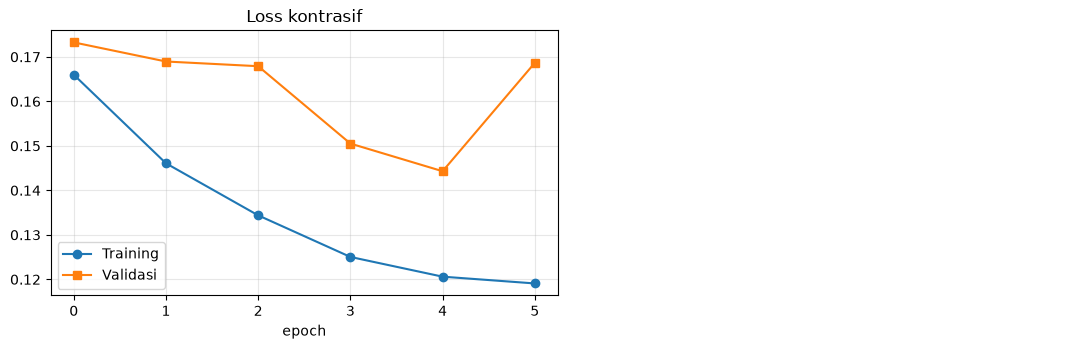

In [17]:
if ADA_MPL:
    h = history.history
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    axes[0].plot(h["loss"], marker="o", label="Training")
    axes[0].plot(h["val_loss"], marker="s", label="Validasi")
    axes[0].set_title("Loss kontrasif"); axes[0].set_xlabel("epoch"); axes[0].grid(alpha=.3); axes[0].legend()
    if "lr" in h:
        axes[1].plot(h["lr"], marker="o")
        axes[1].set_title("Learning rate"); axes[1].set_xlabel("epoch"); axes[1].grid(alpha=.3)
    else:
        axes[1].axis("off")
    plt.tight_layout(); plt.savefig(FIG_DIR / "01_kurva_latih.png", dpi=140, bbox_inches="tight"); plt.show()

## 9. Ensemble Model Lama + Model Baru

Model v2 aktif adalah **ensemble**: embedding model lama dan model hasil fine-tuning digabung,
masing-masing sudah L2-normalized, lalu dibagi `sqrt(n)` sehingga hasil gabungan tetap berpanjang 1.
Jarak gabungan = `sqrt(rata-rata kuadrat jarak tiap model)`.

Kalau model lama tidak tersedia, model baru dipakai langsung. Aplikasi backend tidak perlu diubah:
ia hanya memanggil `model(gambar)` lalu menghitung jarak Euclidean.

In [18]:
def bangun_ensemble(paths):
    inp = keras.Input(shape=(IMG_H, IMG_W, 1), name="signature")
    keluar = []
    for i, p in enumerate(paths):
        m = keras.saving.load_model(p, compile=False)
        keluar.append(keras.Model(m.inputs[0], m.outputs[0], name=f"emb{i}")(inp))
    z = keras.layers.Concatenate(name="gabung")(keluar)
    z = keras.layers.Rescaling(1.0 / float(np.sqrt(len(paths))), name="skala")(z)
    return keras.Model(inp, z, name="ensemble_embedding")


path_final = MODEL_OUT / "embedding_model.keras"
paths = [path_baru]
if lama_path.exists() and BUAT_ENSEMBLE:
    paths = [lama_path, path_baru]
    print("Membuat ensemble: model lama + model baru")
else:
    print("Memakai model baru saja")

if len(paths) == 1:
    shutil.copy2(path_baru, path_final)
else:
    ens = bangun_ensemble(paths)
    ens.save(path_final)

model_final = keras.saving.load_model(path_final, compile=False)
_x = img[:4].astype(np.float32)[..., None] / 255.0
_e1 = model_final.predict(_x, verbose=0)
_e2 = keras.saving.load_model(path_final, compile=False).predict(_x, verbose=0)
assert np.allclose(_e1, _e2, atol=1e-5), "Model hasil muat ulang berbeda"
print("Model final:", path_final, "| keluaran:", _e1.shape, "| norma:", np.round(np.linalg.norm(_e1, axis=1), 4))

Membuat ensemble: model lama + model baru


Model final: D:\Semester 5\Comvis\Project\pendeteksi-ttd\hasil_model_v2\model\embedding_model.keras | keluaran: (4, 128) | norma: [1. 1. 1. 1.]


## 10. Kalibrasi Batas Keputusan (data validasi)

Batas **tidak** dipilih dari data uji. Aturan v2:

- Skor = **jarak terdekat** ke pembanding (untuk k = 1 sama dengan jarak biasa).
- Batas dipilih di validasi, **paling ketat** dari CEDAR dan BHSig260, sehingga FAR tiruan mahir <= target di **setiap** dataset.
- Target aktif `TARGET_FAR = 0.08`; cadangan 0.20 / 0.10 / 0.05 juga dihitung.
- Batas dikalibrasi ulang untuk k = 1..5 pembanding.

Keputusan aplikasi: `jarak <= batas` -> **ASLI**.

In [19]:
GRUP = {"D1": ["CEDAR"], "D2": ["BEN", "HIN"]}


def embed(m, X, bs=256):
    out = []
    for s in range(0, len(X), bs):
        out.append(m.predict(X[s:s + bs].astype(np.float32)[..., None] / 255.0, verbose=0))
    return np.concatenate(out) if out else np.zeros((0, m.output_shape[-1]), np.float32)


def eer_thr(y, d):
    from sklearn.metrics import roc_curve
    fpr, tpr, thr = roc_curve(y, d)
    i = int(np.nanargmin(np.abs((1 - tpr) - fpr)))
    return float((fpr[i] + 1 - tpr[i]) / 2), float(thr[i])


def pasangan_sendiri(folder):
    from sklearn.metrics import roc_curve  # noqa: F401 (pastikan sklearn siap)
    folder = Path(folder)
    m = pd.read_csv(folder / "metadata.csv", encoding="utf-8")
    X, F = [], []
    for f in m.file:
        hasil, steps = preprocess_signature(load_gray(folder / f), "binary", return_steps=True)
        X.append((hasil * 255).astype(np.uint8))
        fe = extract_features(steps.get("potong"))
        F.append(fe if fe is not None else np.zeros(len(NAMA_CIRI), np.float32))
    X, F = np.stack(X), np.stack(F).astype(np.float32)
    idx = {f: i for i, f in enumerate(m.file)}
    own = dict(zip(m.file, m.pemilik))
    org, frg = m[m.label == "asli"], m[m.label == "tiruan"]
    rows = []
    for a, b in itertools.combinations(org.file, 2):
        rows.append((idx[a], idx[b], 0 if own[a] == own[b] else 1, 0 if own[a] == own[b] else 2))
    for _, r in frg.iterrows():
        for a in org[org.pemilik == r.pemilik].file:
            rows.append((idx[a], idx[r.file], 1, 1))
    return X, F, pd.DataFrame(rows, columns=["i1", "i2", "label", "tipe"]), m


pv = PAIRS["val"]
pt = PAIRS["test"]
perlu = np.unique(np.concatenate([pv.i1.values, pv.i2.values, pt.i1.values, pt.i2.values]))
E = np.zeros((len(img), model_final.output_shape[-1]), np.float32)
E[perlu] = embed(model_final, img[perlu])
print("Embedding validasi+uji:", E.shape)

# Foto/scan sendiri (D3) - tidak dipakai memilih batas
ada_own = (FOLDER_OWN / "metadata.csv").exists()
if ada_own:
    Xs, Fs, ps, own_meta = pasangan_sendiri(FOLDER_OWN)
    Es = embed(model_final, Xs)
    print("Foto sendiri:", Xs.shape, "| pasangan:", len(ps), "| pemilik:", own_meta.pemilik.nunique())
else:
    Xs = Fs = ps = own_meta = Es = None
    print("Folder ttd_uji_sendiri tidak ditemukan -> evaluasi D3 dilewati")


def simulasi(E, meta_sub, k, trials=TRIALS, seed=1):
    """Per orang: k pembanding acak. Skor = jarak TERDEKAT ke pembanding."""
    rng = np.random.default_rng(seed)
    ws = sorted(meta_sub.writer.unique())
    gen = {w: meta_sub.index[(meta_sub.writer == w) & meta_sub.is_genuine].to_numpy() for w in ws}
    frg = {w: meta_sub.index[(meta_sub.writer == w) & ~meta_sub.is_genuine].to_numpy() for w in ws}
    ds = meta_sub.groupby("writer").dataset.first().to_dict()
    out = {g: {"asli": [], "mahir": [], "acak": [], "pair": []} for g in GRUP}
    for w in ws:
        grp = next((g for g, dss in GRUP.items() if ds[w] in dss), None)
        if grp is None or len(gen[w]) <= k:
            continue
        lain = np.concatenate([gen[x] for x in ws if x != w and ds[x] == ds[w]]) if len(ws) > 1 else np.array([], int)
        for _ in range(trials):
            refs = rng.choice(gen[w], k, replace=False)
            qg = np.setdiff1d(gen[w], refs)
            oth = rng.choice(lain, min(len(qg), len(lain)), replace=False) if len(lain) else lain
            R = E[refs]
            sk = lambda idx: np.linalg.norm(E[idx][:, None, :] - R[None, :, :], axis=2).min(1)
            out[grp]["asli"].append(sk(qg))
            out[grp]["acak"].append(sk(oth))
            if len(frg[w]):
                out[grp]["mahir"].append(sk(frg[w]))
            if k >= 2:
                out[grp]["pair"].append(np.mean([np.linalg.norm(R[i] - R[j]) for i in range(k) for j in range(i + 1, k)]))
    return {g: {kk: (np.concatenate(v) if v and np.ndim(v[0]) > 0 else np.asarray(v, dtype=float)) for kk, v in d.items()} for g, d in out.items()}


def simulasi_sendiri(Es, own, k, trials=TRIALS, seed=3):
    rng = np.random.default_rng(seed)
    out = {"asli": [], "mahir": [], "acak": [], "pair": []}
    for o in own.pemilik.unique():
        g = own.index[(own.pemilik == o) & (own.label == "asli")].to_numpy()
        f = own.index[(own.pemilik == o) & (own.label == "tiruan")].to_numpy()
        lain = own.index[(own.pemilik != o) & (own.label == "asli")].to_numpy()
        if len(g) <= k:
            continue
        for _ in range(trials):
            refs = rng.choice(g, k, replace=False); qg = np.setdiff1d(g, refs); R = Es[refs]
            sk = lambda idx: np.linalg.norm(Es[idx][:, None, :] - R[None, :, :], axis=2).min(1)
            out["asli"].append(sk(qg)); out["mahir"].append(sk(f)); out["acak"].append(sk(lain))
            if k >= 2:
                out["pair"].append(np.mean([np.linalg.norm(R[i] - R[j]) for i in range(k) for j in range(i + 1, k)]))
    return {kk: (np.concatenate(v) if v and np.ndim(v[0]) > 0 else np.asarray(v, dtype=float)) for kk, v in out.items()}


base_meta = meta_all[~meta_all.aug]
val_meta = base_meta[base_meta.split == "val"]
test_meta = base_meta[base_meta.split == "test"]

SV_VAL = {k: simulasi(E, val_meta, k, trials=TRIALS, seed=1) for k in KS}

THR_K = {}
for t in DAFTAR_TARGET:
    THR_K[t] = {}
    for k in KS:
        batas = []
        for g in GRUP:
            m = SV_VAL[k][g]
            if len(m["mahir"]):
                batas.append(float(np.quantile(m["mahir"], t)))
        THR_K[t][str(k)] = min(batas) if batas else None

KONS_K = {}
for k in KS:
    if k >= 2:
        KONS_K[str(k)] = float(np.quantile(np.concatenate([SV_VAL[k][g]["pair"] for g in GRUP]), 0.95))

baris = []
for k in KS:
    baris.append({"k_pembanding": k, **{f"target_{t:.2f}": THR_K[t][str(k)] for t in DAFTAR_TARGET},
                  "konsistensi_p95": KONS_K.get(str(k))})
TABEL_BATAS = pd.DataFrame(baris)
display(TABEL_BATAS.round(4))
TABEL_BATAS.to_csv(OUT_DIR / "tabel_batas_per_k.csv", index=False)

THR_AKTIF = float(THR_K[TARGET_FAR][str(1)])
print(f"\nBatas aktif k=1 untuk target FAR {TARGET_FAR:.0%}: {THR_AKTIF:.4f}")

Embedding validasi+uji: (28332, 128)


Foto sendiri: (120, 128, 256) | pasangan: 2970 | pemilik: 3


,k_pembanding,target_0.20,target_0.10,target_0.08,target_0.05,konsistensi_p95
0,1,0.4763,0.3979,0.3774,0.3433,NaN
1,2,0.4287,0.3560,0.3396,0.3104,0.5925
2,3,0.4107,0.3403,0.3259,0.2955,0.5469
3,4,0.3964,0.3302,0.3142,0.2874,0.5139
4,5,0.3864,0.3220,0.3050,0.2813,0.4921



Batas aktif k=1 untuk target FAR 8%: 0.3774


## 11. Evaluasi pada Data Uji

Semua orang uji **tidak dipakai** saat training maupun saat memilih batas.

- **D1** = CEDAR uji
- **D2** = BHSig260 Bengali + Hindi uji
- **D3** = foto/scan sendiri (3 pemilik; tiruan oleh penirunya)

Definisi:
- **ROC/AUC**: kelas positif = PALSU; skor = jarak. Sumbu x = FRR (asli salah ditolak), sumbu y = 1 - FAR (tiruan terdeteksi).
- **Confusion**: positif = ASLI. `jarak <= batas` -> ASLI.
- **FAR** = palsu yang lolos; **FRR** = asli yang ditolak.

In [20]:
from sklearn.metrics import roc_curve, roc_auc_score


def auc_eer(y, d):
    if len(np.unique(y)) < 2:
        return None, None
    fpr, tpr, _ = roc_curve(y, d)
    auc = float(roc_auc_score(y, d))
    i = int(np.nanargmin(np.abs((1 - tpr) - fpr)))
    return auc, float((fpr[i] + 1 - tpr[i]) / 2)


def confusion(d, y, tipe, thr):
    asli = d <= thr
    tp = int(np.sum(asli & (y == 0))); fn = int(np.sum(~asli & (y == 0)))
    fp = int(np.sum(asli & (y == 1))); tn = int(np.sum(~asli & (y == 1)))
    n = tp + fn + fp + tn
    div = lambda a, b: float(a / b) if b else None
    rec, spec = div(tp, tp + fn), div(tn, tn + fp)
    prec = div(tp, tp + fp)
    return {
        "batas": float(thr), "n": n, "TP_asli_diterima": tp, "FN_asli_ditolak": fn,
        "FP_palsu_diterima": fp, "TN_palsu_ditolak": tn,
        "akurasi": div(tp + tn, n), "presisi_ASLI": prec, "recall_ASLI": rec,
        "spesifisitas": spec, "F1_ASLI": div(2 * prec * rec, prec + rec) if prec and rec else None,
        "FRR": div(fn, tp + fn), "FAR": div(fp, fp + tn),
        "mahir_lolos": int(np.sum(asli & (tipe == 1))), "mahir_n": int(np.sum(tipe == 1)),
        "acak_lolos": int(np.sum(asli & (tipe == 2))), "acak_n": int(np.sum(tipe == 2)),
    }


def jarak_grup(E, pt, ps=None, Es=None):
    out = {}
    for g, dss in GRUP.items():
        pp = pt[pt.dataset.isin(dss)]
        out[g] = (np.linalg.norm(E[pp.i1.values] - E[pp.i2.values], axis=1), pp.label.values, pp.tipe.values)
    if ps is not None:
        out["D3"] = (np.linalg.norm(Es[ps.i1.values] - Es[ps.i2.values], axis=1), ps.label.values, ps.tipe.values)
    return out


JARAK = {"v2": jarak_grup(E, pt, ps, Es)}

# Model lama, kalau tersedia
thr_lama = None
if lama_path.exists():
    model_lama = keras.saving.load_model(lama_path, compile=False)
    perlu_l = np.unique(np.concatenate([pt.i1.values, pt.i2.values]))
    El = np.zeros((len(img), model_lama.output_shape[-1]), np.float32)
    El[perlu_l] = embed(model_lama, img[perlu_l])
    Esl = embed(model_lama, Xs) if ada_own else None
    JARAK["lama"] = jarak_grup(El, pt, ps, Esl)
    try:
        thr_lama = float(json.load(open(FOLDER_MODEL_LAMA / "config.json", encoding="utf-8"))["threshold"])
    except Exception:
        thr_lama = 0.4825
    print("Model lama dimuat. Batasnya:", thr_lama)
else:
    print("Model lama tidak ada -> evaluasi hanya model v2")

# ---------- AUC / EER ----------
HASIL_AUC = {}
for nama, jg in JARAK.items():
    HASIL_AUC[nama] = {}
    for g, (d, y, _) in jg.items():
        HASIL_AUC[nama][g] = auc_eer(y, d)

baris = []
for g in ("D1", "D2", "D3"):
    if g not in JARAK["v2"]:
        continue
    row = {"dataset": g}
    for nama in JARAK:
        row[f"auc_{nama}"], row[f"eer_{nama}"] = HASIL_AUC[nama][g]
    baris.append(row)
TABEL_AUC = pd.DataFrame(baris)
display(TABEL_AUC.round(4))
TABEL_AUC.to_csv(OUT_DIR / "tabel_auc_eer.csv", index=False)

# ---------- Confusion per target + model lama ----------
CM = {}
for g, (d, y, tipe) in JARAK["v2"].items():
    for t in DAFTAR_TARGET:
        CM[(str(t), g)] = confusion(d, y, tipe, THR_K[t][str(1)])
if "lama" in JARAK:
    for g, (d, y, tipe) in JARAK["lama"].items():
        CM[("lama", g)] = confusion(d, y, tipe, thr_lama)

baris = []
for kunci, c in CM.items():
    tgt, g = kunci
    baris.append({"model": "lama" if tgt == "lama" else "v2", "target_far": "-" if tgt == "lama" else tgt,
                  "dataset": g, **c})
TABEL_CONF = pd.DataFrame(baris)
TABEL_CONF.to_csv(OUT_DIR / "confusion_matrix.csv", index=False, float_format="%.6f")

for g in ("D1", "D2", "D3"):
    if g not in JARAK["v2"]:
        continue
    print(f"\nConfusion matrix {g} (positif = ASLI)")
    kol = [c for c in TABEL_CONF.columns if c in (
        "model", "target_far", "batas", "TP_asli_diterima", "FN_asli_ditolak", "FP_palsu_diterima",
        "TN_palsu_ditolak", "akurasi", "FRR", "FAR", "mahir_lolos", "mahir_n")]
    display(TABEL_CONF[TABEL_CONF.dataset == g][kol].round(4))

Model lama dimuat. Batasnya: 0.4824983775615692


,dataset,auc_v2,eer_v2,auc_lama,eer_lama
0,D1,0.9179,0.1633,0.9215,0.1650
1,D2,0.9116,0.1677,0.8251,0.2526
2,D3,0.8765,0.2068,0.8926,0.1921



Confusion matrix D1 (positif = ASLI)


,model,target_far,batas,TP_asli_diterima,FN_asli_ditolak,FP_palsu_diterima,TN_palsu_ditolak,akurasi,FRR,FAR,mahir_lolos,mahir_n
0,v2,0.2,0.4763,622,278,75,825,0.8039,0.3089,0.0833,75,675
1,v2,0.1,0.3979,502,398,36,864,0.7589,0.4422,0.0400,36,675
2,v2,0.08,0.3774,466,434,33,867,0.7406,0.4822,0.0367,33,675
3,v2,0.05,0.3433,403,497,20,880,0.7128,0.5522,0.0222,20,675
12,lama,-,0.4825,720,180,112,788,0.8378,0.2000,0.1244,109,675



Confusion matrix D2 (positif = ASLI)


,model,target_far,batas,TP_asli_diterima,FN_asli_ditolak,FP_palsu_diterima,TN_palsu_ditolak,akurasi,FRR,FAR,mahir_lolos,mahir_n
4,v2,0.2,0.4763,3351,549,826,3074,0.8237,0.1408,0.2118,685,2925
5,v2,0.1,0.3979,2989,911,409,3491,0.8308,0.2336,0.1049,339,2925
6,v2,0.08,0.3774,2865,1035,321,3579,0.8262,0.2654,0.0823,269,2925
7,v2,0.05,0.3433,2602,1298,207,3693,0.8071,0.3328,0.0531,174,2925
13,lama,-,0.4825,3775,125,2826,1074,0.6217,0.0321,0.7246,2306,2925



Confusion matrix D3 (positif = ASLI)


,model,target_far,batas,TP_asli_diterima,FN_asli_ditolak,FP_palsu_diterima,TN_palsu_ditolak,akurasi,FRR,FAR,mahir_lolos,mahir_n
8,v2,0.2,0.4763,455,115,510,1890,0.7896,0.2018,0.2125,451,1200
9,v2,0.1,0.3979,366,204,299,2101,0.8306,0.3579,0.1246,282,1200
10,v2,0.08,0.3774,346,224,253,2147,0.8394,0.3930,0.1054,243,1200
11,v2,0.05,0.3433,311,259,191,2209,0.8485,0.4544,0.0796,188,1200
14,lama,-,0.4825,517,53,683,1717,0.7522,0.0930,0.2846,633,1200


In [21]:
# ---------- Evaluasi per jumlah pembanding (k = 1..5) ----------
SV_TEST = {k: simulasi(E, test_meta, k, trials=TRIALS, seed=2) for k in KS}
SV_OWN = ({k: simulasi_sendiri(Es, own_meta, k, trials=TRIALS, seed=3) for k in KS} if ada_own else None)

METRIK_K = {}
BP = {g: {} for g in GRUP}
if ada_own:
    BP["D3"] = {}
for k in KS:
    thr = THR_K[TARGET_FAR][str(k)]
    METRIK_K[str(k)] = {}
    for g in GRUP:
        m = SV_TEST[k][g]
        S = np.concatenate([m["asli"], m["mahir"], m["acak"]])
        Y = np.concatenate([np.zeros(len(m["asli"])), np.ones(len(m["mahir"])), np.ones(len(m["acak"]))])
        auc, eer = auc_eer(Y, S)
        METRIK_K[str(k)][g] = {
            "FAR_skilled_forgery": float(np.mean(m["mahir"] <= thr)) if len(m["mahir"]) else None,
            "FAR_random_forgery": float(np.mean(m["acak"] <= thr)) if len(m["acak"]) else None,
            "FRR": float(np.mean(m["asli"] > thr)) if len(m["asli"]) else None,
        }
        BP[g][str(k)] = {"auc": auc, "eer": eer, "FAR": METRIK_K[str(k)][g]["FAR_skilled_forgery"],
                         "FRR": METRIK_K[str(k)][g]["FRR"]}
    if SV_OWN is not None:
        m = SV_OWN[k]
        S = np.concatenate([m["asli"], m["mahir"], m["acak"]])
        Y = np.concatenate([np.zeros(len(m["asli"])), np.ones(len(m["mahir"])), np.ones(len(m["acak"]))])
        auc, eer = auc_eer(Y, S)
        METRIK_K[str(k)]["D3"] = {
            "FAR_skilled_forgery": float(np.mean(m["mahir"] <= thr)) if len(m["mahir"]) else None,
            "FAR_random_forgery": float(np.mean(m["acak"] <= thr)) if len(m["acak"]) else None,
            "FRR": float(np.mean(m["asli"] > thr)) if len(m["asli"]) else None,
        }
        BP["D3"][str(k)] = {"auc": auc, "eer": eer, "FAR": METRIK_K[str(k)]["D3"]["FAR_skilled_forgery"],
                            "FRR": METRIK_K[str(k)]["D3"]["FRR"]}

baris = []
for k in KS:
    row = {"k_pembanding": k, "batas": THR_K[TARGET_FAR][str(k)]}
    for g, v in METRIK_K[str(k)].items():
        row[f"{g}_FAR_mahir"] = v["FAR_skilled_forgery"]
        row[f"{g}_FAR_acak"] = v["FAR_random_forgery"]
        row[f"{g}_FRR"] = v["FRR"]
    baris.append(row)
TABEL_PER_K = pd.DataFrame(baris)
display(TABEL_PER_K.round(4))
TABEL_PER_K.to_csv(OUT_DIR / "tabel_metrik_per_k.csv", index=False)

baris = [{"dataset": g, "k_pembanding": int(k), **v} for g, d in BP.items() for k, v in d.items()]
TABEL_MULTI = pd.DataFrame(baris)
display(TABEL_MULTI.round(4))
TABEL_MULTI.to_csv(OUT_DIR / "tabel_banyak_pembanding.csv", index=False)

,k_pembanding,batas,D1_FAR_mahir,D1_FAR_acak,D1_FRR,D2_FAR_mahir,D2_FAR_acak,D2_FRR,D3_FAR_mahir,D3_FAR_acak,D3_FRR
0,1,0.3774,0.0472,0.0005,0.4903,0.0845,0.0536,0.2577,0.2092,0.0092,0.3789
1,2,0.3396,0.0412,0.0003,0.3937,0.0784,0.0504,0.2083,0.2208,0.0017,0.3148
2,3,0.3259,0.0512,0.0003,0.3677,0.0800,0.0519,0.1742,0.2242,0.0000,0.2539
3,4,0.3142,0.0502,0.0000,0.3389,0.0764,0.0490,0.1596,0.2167,0.0000,0.2562
4,5,0.3050,0.0433,0.0000,0.3123,0.0732,0.0473,0.1509,0.2225,0.0000,0.2767


,dataset,k_pembanding,auc,eer,FAR,FRR
0,D1,1,0.9367,0.1386,0.0472,0.4903
1,D1,2,0.9549,0.1166,0.0412,0.3937
2,D1,3,0.9575,0.1093,0.0512,0.3677
3,D1,4,0.9618,0.1032,0.0502,0.3389
4,D1,5,0.9682,0.0868,0.0433,0.3123
5,D2,1,0.9250,0.1545,0.0845,0.2577
6,D2,2,0.9481,0.1261,0.0784,0.2083
7,D2,3,0.9575,0.1147,0.0800,0.1742
8,D2,4,0.9629,0.1065,0.0764,0.1596
9,D2,5,0.9666,0.1005,0.0732,0.1509


## 12. Grafik ROC dan Confusion Matrix

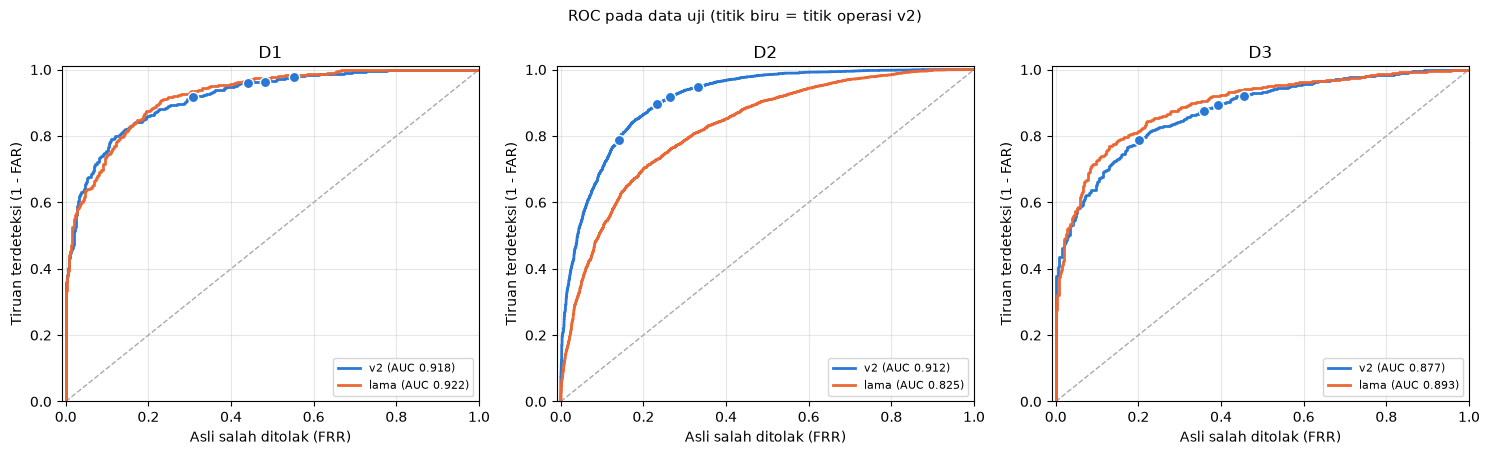

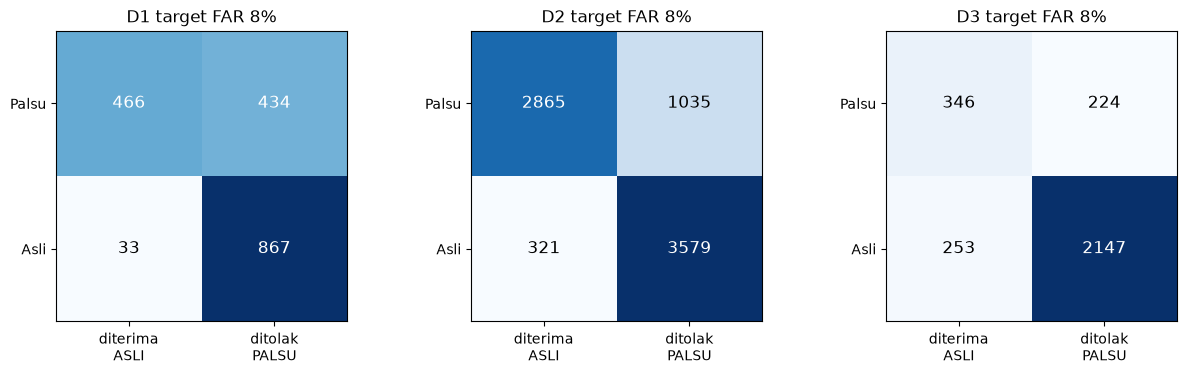

In [22]:
if ADA_MPL:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
    warna = {"lama": "#EB6834", "v2": "#2A78D6"}
    for ax, g in zip(axes, ("D1", "D2", "D3")):
        if g not in JARAK["v2"]:
            ax.axis("off"); continue
        ax.plot([0, 1], [0, 1], ls="--", color="#aaaaaa", lw=1)
        for nama in JARAK:
            d, y, _ = JARAK[nama][g]
            fpr, tpr, _ = roc_curve(y, d)
            ax.plot(fpr, tpr, color=warna[nama], lw=2, label=f"{nama} (AUC {HASIL_AUC[nama][g][0]:.3f})")
        d, y, _ = JARAK["v2"][g]
        for t in DAFTAR_TARGET:
            thr = THR_K[t][str(1)]
            ax.scatter([np.mean(d[y == 0] > thr)], [np.mean(d[y == 1] > thr)], s=55,
                       color="#2A78D6", edgecolor="white", zorder=5)
        ax.set_title(f"{g}"); ax.set_xlabel("Asli salah ditolak (FRR)"); ax.set_ylabel("Tiruan terdeteksi (1 - FAR)")
        ax.set_xlim(-0.01, 1); ax.set_ylim(0, 1.01); ax.grid(alpha=.3); ax.legend(fontsize=8)
    plt.suptitle("ROC pada data uji (titik biru = titik operasi v2)", fontsize=11)
    plt.tight_layout(); plt.savefig(FIG_DIR / "02_roc.png", dpi=140, bbox_inches="tight"); plt.show()

    # Confusion matrix pada target aktif
    grup_plot = [g for g in ("D1", "D2", "D3") if g in JARAK["v2"]]
    fig, axes = plt.subplots(1, len(grup_plot), figsize=(4.2 * len(grup_plot), 3.8), squeeze=False)
    for ax, g in zip(axes[0], grup_plot):
        c = CM[(str(TARGET_FAR), g)]
        M = np.array([[c["TP_asli_diterima"], c["FN_asli_ditolak"]],
                      [c["FP_palsu_diterima"], c["TN_palsu_ditolak"]]], float)
        ax.imshow(M, cmap="Blues")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{int(M[i, j])}", ha="center", va="center",
                        color="white" if M[i, j] > M.max() * 0.5 else "black", fontsize=12)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["diterima\nASLI", "ditolak\nPALSU"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Palsu", "Asli"])
        ax.set_title(f"{g} target FAR {TARGET_FAR:.0%}")
    plt.tight_layout(); plt.savefig(FIG_DIR / "03_confusion.png", dpi=140, bbox_inches="tight"); plt.show()
else:
    print("matplotlib tidak terpasang -> grafik dilewati")

## 13. Analisis Tambahan (opsional tapi disarankan)

### 13a. Ketahanan terhadap gangguan seperti foto HP

Sisi "diperiksa" pada pasangan uji sengaja diberi bayangan, buram, miring, redup, noise, kompresi, dan gabungan `foto_hp`.
Batas tidak diubah. Ini menguji apakah pengolahan citra + augmentasi v2 benar-benar membantu.

,dataset,kondisi,AUC,EER,akurasi,FAR_mahir,FRR
0,D1,bersih,0.9179,0.1633,0.7406,0.0489,0.4822
1,D1,bayangan,0.9183,0.1650,0.7417,0.0474,0.4811
2,D1,buram,0.8833,0.1956,0.6750,0.0237,0.6322
3,D1,miring,0.8990,0.1733,0.7011,0.0430,0.5656
4,D1,redup,0.9179,0.1644,0.7406,0.0489,0.4822
5,D1,noise,0.9184,0.1633,0.7406,0.0444,0.4856
6,D1,foto_hp,0.8857,0.1928,0.6839,0.0474,0.5967
7,D2,bersih,0.9116,0.1677,0.8262,0.0920,0.2654
8,D2,bayangan,0.9117,0.1681,0.8265,0.0920,0.2646
9,D2,buram,0.7517,0.3253,0.6256,0.0848,0.6692


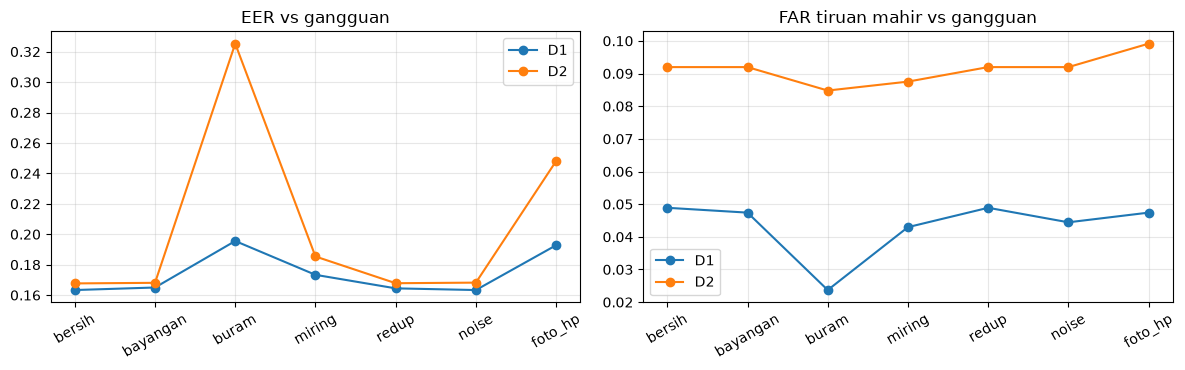

In [23]:
if JALANKAN_ANALISIS_TAMBAHAN:
    def uji_ketahanan(g, P, E_model, thr):
        uniq = np.unique(np.concatenate([P.i1.values, P.i2.values])).astype(int)
        gray_cache = {int(u): load_gray(meta_all.path[int(u)]) for u in uniq}
        pos = {int(u): i for i, u in enumerate(uniq)}
        baris = []
        for c in ["bersih"] + list(KONDISI):
            if c == "bersih":
                d = np.linalg.norm(E_model[P.i1.values] - E_model[P.i2.values], axis=1)
            else:
                rng = np.random.default_rng(SEED + sum(map(ord, c)))
                arrs = []
                for u in uniq:
                    a, _ = preprocess_all(KONDISI[c](gray_cache[int(u)], rng), ("binary",))
                    arrs.append((a["binary"] * 255).astype(np.uint8))
                Ep = embed(model_final, np.stack(arrs))
                d = np.linalg.norm(E_model[P.i1.values] - Ep[[pos[int(i)] for i in P.i2.values]], axis=1)
            y, tipe = P.label.values, P.tipe.values
            auc, eer = auc_eer(y, d)
            m = confusion(d, y, tipe, thr)
            baris.append({"kondisi": c, "AUC": auc, "EER": eer, "akurasi": m["akurasi"],
                          "FAR_mahir": m["mahir_lolos"] / max(1, m["mahir_n"]), "FRR": m["FRR"]})
        return pd.DataFrame(baris)

    rows = []
    for g, dss in GRUP.items():
        P = pt[pt.dataset.isin(dss)]
        t = uji_ketahanan(g, P, E, THR_AKTIF)
        t.insert(0, "dataset", g)
        rows.append(t)
    TABEL_ROB = pd.concat(rows, ignore_index=True)
    display(TABEL_ROB.round(4))
    TABEL_ROB.to_csv(OUT_DIR / "tabel_ketahanan_foto.csv", index=False)

    if ADA_MPL:
        fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
        for g in TABEL_ROB.dataset.unique():
            a = TABEL_ROB[TABEL_ROB.dataset == g]
            axes[0].plot(a.kondisi, a.EER, marker="o", label=g)
            axes[1].plot(a.kondisi, a.FAR_mahir, marker="o", label=g)
        axes[0].set_title("EER vs gangguan"); axes[1].set_title("FAR tiruan mahir vs gangguan")
        for ax in axes:
            ax.grid(alpha=.3); ax.tick_params(axis="x", rotation=30); ax.legend()
        plt.tight_layout(); plt.savefig(FIG_DIR / "04_ketahanan.png", dpi=140, bbox_inches="tight"); plt.show()
else:
    TABEL_ROB = None
    print("Analisis ketahanan dilewati")

### 13b. Uji goyang: apakah keputusan stabil?

Setiap tanda tangan diperiksa pada beberapa versi yang digeser/diputar/diperbesar sedikit. Kalau hasilnya berubah-ubah,
model dianggap **ragu**. Ambang ragu (`ragu_z`) dan lebar zona ragu (`ragu_margin`) dikalibrasi di validasi
pada bagian paling tidak yakin (`ABSTAIN_FRAC`).

In [24]:
def jarak_goyang(m, images, P, n=N_SHAKE, seed=SEED, chunk=150):
    uniq = np.unique(np.concatenate([P.i1.values, P.i2.values])).astype(int)
    pos = {int(u): i for i, u in enumerate(uniq)}
    Evar = np.empty((len(uniq), n, m.output_shape[-1]), np.float32)
    for s in range(0, len(uniq), chunk):
        part = uniq[s:s + chunk]
        V = np.concatenate([shake_variants(images[u].astype(np.float32) / 255.0, n, seed + int(u)) for u in part])
        Evar[s:s + len(part)] = m.predict(V, batch_size=128, verbose=0).reshape(len(part), n, -1)
    A = Evar[[pos[int(i)] for i in P.i1.values]]
    B = Evar[[pos[int(i)] for i in P.i2.values]]
    return np.linalg.norm(A - B, axis=2)


def keyakinan(dm, thr):
    return np.abs(dm.mean(1) - thr) / (dm.std(1) + 1e-6)


if JALANKAN_ANALISIS_TAMBAHAN:
    sub = pv.sample(min(800, len(pv)), random_state=SEED).reset_index(drop=True)
    dm_val = jarak_goyang(model_final, img, sub)
    z_val = keyakinan(dm_val, THR_AKTIF)
    RAGU_Z = float(np.quantile(z_val, ABSTAIN_FRAC))
    d_val = np.linalg.norm(E[sub.i1.values] - E[sub.i2.values], axis=1)
    RAGU_MARGIN = float(np.quantile(np.abs(d_val - THR_AKTIF), ABSTAIN_FRAC))
    print(f"ragu_z = {RAGU_Z:.3f} | ragu_margin = {RAGU_MARGIN:.4f}")

    GOYANG = {}
    sources = {g: (pt[pt.dataset.isin(dss)].reset_index(drop=True), img, E) for g, dss in GRUP.items()}
    if ada_own:
        sources["D3"] = (ps, Xs, Es)

    for g, (P, IM, EE) in sources.items():
        dm = jarak_goyang(model_final, IM, P)
        z = keyakinan(dm, THR_AKTIF)
        d = np.linalg.norm(EE[P.i1.values] - EE[P.i2.values], axis=1)
        y = P.label.values
        benar = ((d <= THR_AKTIF) == (y == 0))
        yakin = z >= RAGU_Z
        GOYANG[g] = {
            "akurasi_semua": float(benar.mean()),
            "akurasi_yakin": float(benar[yakin].mean()) if yakin.any() else None,
            "akurasi_ragu": float(benar[~yakin].mean()) if (~yakin).any() else None,
            "porsi_ragu": float((~yakin).mean()),
            "FAR_semua": float(np.mean((d <= THR_AKTIF)[y == 1])),
            "FAR_hanya_yakin": float(np.sum((d <= THR_AKTIF)[y == 1] & yakin[y == 1]) / max(1, np.sum(y == 1))),
        }
    display(pd.DataFrame(GOYANG).T.round(4))
else:
    RAGU_Z = RAGU_MARGIN = None
    GOYANG = {}
    print("Uji goyang dilewati")

ragu_z = 1.204 | ragu_margin = 0.0757


,akurasi_semua,akurasi_yakin,akurasi_ragu,porsi_ragu,FAR_semua,FAR_hanya_yakin
D1,0.7406,0.7575,0.6756,0.2072,0.0367,0.0089
D2,0.8262,0.8651,0.6851,0.2162,0.0823,0.0274
D3,0.8394,0.8907,0.5606,0.1556,0.1054,0.0512


### 13c. Fusi ciri forensik dengan model

Jarak model digabung dengan 8 selisih ciri klasik memakai regresi logistik.
Dilatih di data validasi, diuji di data uji. Tujuannya: apakah ciri forensik menurunkan error,
dan sekaligus menyediakan bahan laporan yang bisa dijelaskan (*explainable*).

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler


def X_fusi(P, EE, FF):
    dist = np.linalg.norm(EE[P.i1.values] - EE[P.i2.values], axis=1)
    diffs = np.stack([feature_diffs(FF[a], FF[b]) for a, b in zip(P.i1.values, P.i2.values)])
    return np.column_stack([dist, diffs])


if JALANKAN_ANALISIS_TAMBAHAN:
    Xv = X_fusi(pv, E, feat)
    sc = StandardScaler().fit(Xv)
    lr = LogisticRegression(max_iter=3000, C=1.0).fit(sc.transform(Xv), pv.label.values)
    sv = lr.decision_function(sc.transform(Xv))
    THR_FUSI = float(np.quantile(sv[pv.tipe.values == 1], TARGET_FAR))

    baris = []
    sumber = {g: (pt[pt.dataset.isin(dss)], E, feat) for g, dss in GRUP.items()}
    if ada_own:
        sumber["D3"] = (ps, Es, Fs)
    for g, (P, EE, FF) in sumber.items():
        ds_ = np.linalg.norm(EE[P.i1.values] - EE[P.i2.values], axis=1)
        sf = lr.decision_function(sc.transform(X_fusi(P, EE, FF)))
        for nama, s, thr in (("model saja", ds_, THR_AKTIF), ("fusi (model+ciri)", sf, THR_FUSI)):
            y, tipe = P.label.values, P.tipe.values
            auc, eer = auc_eer(y, s)
            m = confusion(s, y, tipe, thr)
            baris.append({"dataset": g, "skenario": nama, "AUC": auc, "EER": eer,
                          "akurasi": m["akurasi"], "FAR_mahir": m["mahir_lolos"] / max(1, m["mahir_n"]), "FRR": m["FRR"]})
    TABEL_FUSI = pd.DataFrame(baris)
    display(TABEL_FUSI.round(4))
    TABEL_FUSI.to_csv(OUT_DIR / "tabel_fusi.csv", index=False)

    # Batas laporan forensik: p75/p95 selisih ciri pada pasangan ASLI di data latih
    ptr = PAIRS["train"]
    gp = ptr[ptr.label == 0]
    dg = np.stack([feature_diffs(feat[a], feat[b]) for a, b in zip(gp.i1.values, gp.i2.values)])
    FORENSIK_BATAS = {n: [float(np.percentile(dg[:, i], 75)), float(np.percentile(dg[:, i], 95))]
                      for i, n in enumerate(NAMA_CIRI)}

    FUSI_CFG = {
        "fitur": ["jarak_model"] + NAMA_CIRI,
        "mean": sc.mean_.tolist(), "scale": sc.scale_.tolist(),
        "coef": lr.coef_[0].tolist(), "intercept": float(lr.intercept_[0]),
        "threshold": THR_FUSI, "hasil": TABEL_FUSI.to_dict(orient="records"),
    }

    contoh = pt[(pt.tipe == 1)].iloc[0]
    print("\nContoh laporan forensik untuk satu pasangan tiruan mahir:")
    for r in explain(feat[int(contoh.i1)], feat[int(contoh.i2)], FORENSIK_BATAS):
        print("  -", r["kalimat"])
else:
    TABEL_FUSI = None
    FORENSIK_BATAS = None
    FUSI_CFG = None
    print("Fusi forensik dilewati")

,dataset,skenario,AUC,EER,akurasi,FAR_mahir,FRR
0,D1,model saja,0.9179,0.1633,0.7406,0.0489,0.4822
1,D1,fusi (model+ciri),0.9101,0.1600,0.7183,0.0741,0.5078
2,D2,model saja,0.9116,0.1677,0.8262,0.0920,0.2654
3,D2,fusi (model+ciri),0.9281,0.1514,0.8451,0.0920,0.2279
4,D3,model saja,0.8765,0.2068,0.8394,0.2025,0.3930
5,D3,fusi (model+ciri),0.8770,0.1994,0.8603,0.0442,0.6333



Contoh laporan forensik untuk satu pasangan tiruan mahir:
  - Bentuk (lebar dibanding tinggi): pembanding 4.43, diperiksa 3.59 (agak beda).
  - Kepadatan tinta: pembanding 8.0%, diperiksa 10.7% (agak beda).
  - Kemiringan umum: pembanding 3 derajat, diperiksa 2 derajat (mirip).
  - Ketebalan goresan: pembanding 3.03, diperiksa 3.66 (mirip).
  - Jumlah bagian terpisah (angkat pena): pembanding 4 bagian, diperiksa 9 bagian (agak beda).
  - Panjang total goresan: pembanding 2.48, diperiksa 2.71 (mirip).
  - Letak pusat tinta (kiri-kanan): pembanding 48%, diperiksa 50% (agak beda).
  - Letak pusat tinta (atas-bawah): pembanding 50%, diperiksa 51% (mirip).


## 14. Menyimpan Config untuk Aplikasi

`config.json` berisi model, batas keputusan (k = 1..5), metrik per dataset, fusi ciri, batas forensik,
dan kalibrasi Uji Goyang. Salin isi folder `hasil_model_v2/model/` ke `demo_model_files_v2/` aplikasi
(model `.keras`, `config.json`, dan tiga modul `.py`), lalu jalankan ulang backend.

In [26]:
def bersih(o):
    if isinstance(o, dict):
        return {str(k): bersih(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [bersih(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if (isinstance(o, float) and np.isnan(o)) else float(o)
    if isinstance(o, np.integer):
        return int(o)
    return o


# Status akhir ringkas (model + Uji Goyang + fusi), seperti backend
status_hasil = {}
if JALANKAN_ANALISIS_TAMBAHAN and GOYANG and FUSI_CFG is not None:
    for g, (P, EE, FF) in sumber.items():
        dm = jarak_goyang(model_final, (Xs if g == "D3" else img), P)
        z = keyakinan(dm, THR_AKTIF)
        d = np.linalg.norm(EE[P.i1.values] - EE[P.i2.values], axis=1)
        sf = lr.decision_function(sc.transform(X_fusi(P, EE, FF)))
        status_asli = (d <= THR_AKTIF) & (z >= RAGU_Z) & (sf <= THR_FUSI)
        y = P.label.values
        status_hasil[g] = {
            "FAR_keputusan_model": float(np.mean((d <= THR_AKTIF)[y == 1])),
            "FAR_status_ASLI": float(np.mean(status_asli[y == 1])),
            "FAR_status_ASLI_mahir": float(np.mean(status_asli[P.tipe.values == 1])) if (P.tipe.values == 1).any() else None,
            "asli_dikenali_ASLI": float(np.mean(status_asli[y == 0])),
            "asli_jadi_BELUM_YAKIN_atau_PALSU": float(np.mean(~status_asli[y == 0])),
            "n": int(len(y)),
        }
    print("Status akhir (model + Uji Goyang + fusi):")
    display(pd.DataFrame(status_hasil).T.round(4))

eval_per_dataset = {}
for g, (d, y, tipe) in JARAK["v2"].items():
    m = confusion(d, y, tipe, THR_AKTIF)
    eval_per_dataset[g] = {"auc": HASIL_AUC["v2"][g][0], "eer": HASIL_AUC["v2"][g][1], **m}

titik = {}
for t in DAFTAR_TARGET:
    titik[str(t)] = {}
    for g in JARAK["v2"]:
        titik[str(t)][g] = confusion(*JARAK["v2"][g], THR_K[t][str(1)])

cfg = {
    "model": "v2: CEDAR + BHSig260 (Bengali, Hindi), fokus FAR tiruan mahir",
    "versi": "v2-notebook",
    "img_h": IMG_H, "img_w": IMG_W, "preprocess_mode": "binary",
    "threshold": THR_AKTIF, "margin": MARGIN,
    "catatan_metrik": (
        "D1 = CEDAR uji, D2 = BHSig260 Bengali+Hindi uji, D3 = foto/scan sendiri. Semua orang uji tidak dipakai "
        "saat training. Batas dipilih di validasi (paling ketat dari CEDAR dan BHSig260) sehingga FAR tiruan mahir "
        f"validasi <= {TARGET_FAR:.0%} di tiap dataset. Keputusan: jarak <= batas -> ASLI. Skor = jarak terdekat."
    ),
    "tensorflow_version": tf.__version__,
    "keras_version": keras.__version__,
    "data_latih": {
        "CEDAR": "55 orang", "BHSig260-Bengali": "100 orang", "BHSig260-Hindi": "160 orang",
        "pembagian": "per orang 70/15/15", "versi_foto_hp_untuk_latih": True,
    },
    "metrics": {
        "test_auc": eval_per_dataset.get("D1", {}).get("auc"),
        "test_eer": eval_per_dataset.get("D1", {}).get("eer"),
        "test_accuracy": eval_per_dataset.get("D1", {}).get("akurasi"),
        "test_FRR": eval_per_dataset.get("D1", {}).get("FRR"),
        "test_FAR": eval_per_dataset.get("D1", {}).get("FAR"),
        "test_FAR_skilled_forgery": (eval_per_dataset.get("D1", {}).get("mahir_lolos", 0) /
                                     max(1, eval_per_dataset.get("D1", {}).get("mahir_n", 1))),
        "per_dataset": eval_per_dataset,
    },
    "titik_operasi": titik,
    "threshold_per_k": THR_K[TARGET_FAR],
    "konsistensi_pembanding": KONS_K,
    "skor_k": "min",
    "metrik_per_k": METRIK_K,
    "target_far_per_k": TARGET_FAR,
    "status_akhir": status_hasil,
    "fusi": FUSI_CFG,
    "forensik_batas": FORENSIK_BATAS,
    "goyang": {"n": N_SHAKE, "ragu_z": RAGU_Z, "ragu_margin": RAGU_MARGIN, "abstain_frac": ABSTAIN_FRAC, "hasil": GOYANG},
    "banyak_pembanding": BP,
}

for f in ("preprocess.py", "forensik.py", "gangguan.py"):
    shutil.copy2(MODUL_DIR / f, MODEL_OUT / f)
with open(MODEL_OUT / "config.json", "w", encoding="utf-8") as f:
    json.dump(bersih(cfg), f, indent=2, ensure_ascii=False)

sha = hashlib.sha256(open(path_final, "rb").read()).hexdigest().upper()
print("Config tersimpan:", MODEL_OUT / "config.json")
print("SHA256 model:", sha)
print("Batas k=1 target", TARGET_FAR, ":", THR_AKTIF)
print("Batas per k:", THR_K[TARGET_FAR])

Status akhir (model + Uji Goyang + fusi):


,FAR_keputusan_model,FAR_status_ASLI,FAR_status_ASLI_mahir,asli_dikenali_ASLI,asli_jadi_BELUM_YAKIN_atau_PALSU,n
D1,0.0367,0.0056,0.0074,0.2100,0.7900,1800.0
D2,0.0823,0.0115,0.0113,0.4826,0.5174,7800.0
D3,0.1054,0.0142,0.0283,0.1860,0.8140,2970.0


Config tersimpan: D:\Semester 5\Comvis\Project\pendeteksi-ttd\hasil_model_v2\model\config.json
SHA256 model: 211EDA03F3570A3A6044F792808504EE6955D7AB6BD3DCD0F111FDB9E7DB55E0
Batas k=1 target 0.08 : 0.37744781374931335
Batas per k: {'1': 0.37744781374931335, '2': 0.33957597613334656, '3': 0.3258904814720154, '4': 0.3142397403717041, '5': 0.30504727363586426}


In [27]:
# Simpan ringkasan markdown + paket zip siap dipakai aplikasi
baris = []
baris.append("# Ringkasan Model v2 (hasil notebook)\n")
baris.append(f"- Model: `{path_final.name}`")
baris.append(f"- Target FAR: **{TARGET_FAR:.0%}**")
baris.append(f"- Batas k=1: **{THR_AKTIF:.4f}**")
baris.append(f"- Batas k=1..5: {', '.join(f'{THR_K[TARGET_FAR][str(k)]:.4f}' for k in KS)}")
baris.append(f"- SHA256: `{sha}`\n")
baris.append("## AUC / EER pada data uji\n")
baris.append("| Data uji | AUC | EER |")
baris.append("|---|---|---|")
for g in ("D1", "D2", "D3"):
    if g in HASIL_AUC["v2"]:
        a, e = HASIL_AUC["v2"][g]
        baris.append(f"| {g} | {a:.4f} | {e * 100:.1f}% |")
baris.append("\n## Confusion matrix (target aktif, positif = ASLI)\n")
baris.append("| Data uji | Batas | TP | FN | FP | TN | Akurasi | FRR | FAR | Tiruan mahir lolos |")
baris.append("|---|---|---|---|---|---|---|---|---|---|")
for g in ("D1", "D2", "D3"):
    if g in eval_per_dataset:
        c = eval_per_dataset[g]
        baris.append(f"| {g} | {c['batas']:.4f} | {c['TP_asli_diterima']} | {c['FN_asli_ditolak']} | "
                     f"{c['FP_palsu_diterima']} | {c['TN_palsu_ditolak']} | {c['akurasi'] * 100:.1f}% | "
                     f"{c['FRR'] * 100:.1f}% | {c['FAR'] * 100:.1f}% | {c['mahir_lolos']}/{c['mahir_n']} |")
baris.append("\n## Batas per jumlah pembanding\n")
baris.append("| k | " + " | ".join(f"target {t:.2f}" for t in DAFTAR_TARGET) + " |")
baris.append("|---|" + "---|" * len(DAFTAR_TARGET))
for k in KS:
    baris.append(f"| {k} | " + " | ".join(f"{THR_K[t][str(k)]:.4f}" for t in DAFTAR_TARGET) + " |")
baris.append("\n## Catatan\n")
baris.append("- Batas dipilih hanya dari validasi; data uji tidak dipakai memilih apa pun.")
baris.append("- FAR dan FRR saling menukar. Target FAR kecil membayar dengan lebih banyak asli ditolak / 'BELUM YAKIN'.")
baris.append("- D3 hanya 3 pemilik, jadi angkanya bersifat indikasi.")
teks = "\n".join(baris)
open(OUT_DIR / "ringkasan_model_v2.md", "w", encoding="utf-8").write(teks + "\n")
print(teks)

paket = OUT_DIR / "model_v2_paket.zip"
with zipfile.ZipFile(paket, "w", zipfile.ZIP_DEFLATED) as z:
    for f in ("embedding_model.keras", "config.json", "preprocess.py", "forensik.py", "gangguan.py"):
        z.write(MODEL_OUT / f, f)
print("\nPaket aplikasi:", paket)
print("Isi:", zipfile.ZipFile(paket).namelist())
print("\nSemua hasil ada di:", OUT_DIR)

# Ringkasan Model v2 (hasil notebook)

- Model: `embedding_model.keras`
- Target FAR: **8%**
- Batas k=1: **0.3774**
- Batas k=1..5: 0.3774, 0.3396, 0.3259, 0.3142, 0.3050
- SHA256: `211EDA03F3570A3A6044F792808504EE6955D7AB6BD3DCD0F111FDB9E7DB55E0`

## AUC / EER pada data uji

| Data uji | AUC | EER |
|---|---|---|
| D1 | 0.9179 | 16.3% |
| D2 | 0.9116 | 16.8% |
| D3 | 0.8765 | 20.7% |

## Confusion matrix (target aktif, positif = ASLI)

| Data uji | Batas | TP | FN | FP | TN | Akurasi | FRR | FAR | Tiruan mahir lolos |
|---|---|---|---|---|---|---|---|---|---|
| D1 | 0.3774 | 466 | 434 | 33 | 867 | 74.1% | 48.2% | 3.7% | 33/675 |
| D2 | 0.3774 | 2865 | 1035 | 321 | 3579 | 82.6% | 26.5% | 8.2% | 269/2925 |
| D3 | 0.3774 | 346 | 224 | 253 | 2147 | 83.9% | 39.3% | 10.5% | 243/1200 |

## Batas per jumlah pembanding

| k | target 0.20 | target 0.10 | target 0.08 | target 0.05 |
|---|---|---|---|---|
| 1 | 0.4763 | 0.3979 | 0.3774 | 0.3433 |
| 2 | 0.4287 | 0.3560 | 0.3396 | 0.3104 |
| 3 | 0


Paket aplikasi: D:\Semester 5\Comvis\Project\pendeteksi-ttd\hasil_model_v2\model_v2_paket.zip
Isi: ['embedding_model.keras', 'config.json', 'preprocess.py', 'forensik.py', 'gangguan.py']

Semua hasil ada di: D:\Semester 5\Comvis\Project\pendeteksi-ttd\hasil_model_v2


## 15. Ringkasan dan Catatan Penting

### Keluaran

| Berkas | Isi |
|---|---|
| `hasil_model_v2/model/embedding_model.keras` | Model final (ensemble lama + fine-tuning v2) |
| `hasil_model_v2/model/embedding_model_baru.keras` | Model hasil fine-tuning saja |
| `hasil_model_v2/model/config.json` | Batas keputusan, metrik, fusi, forensik, kalibrasi goyang |
| `hasil_model_v2/model/model_v2_paket.zip` | Paket siap salin ke aplikasi |
| `hasil_model_v2/tabel_*.csv` | AUC/EER, confusion matrix, batas per k, ketahanan, fusi |
| `hasil_model_v2/figures/` | Kurva training, ROC, confusion matrix, ketahanan |
| `hasil_model_v2/ringkasan_model_v2.md` | Ringkasan siap tempel ke laporan |

### Angka acuan model v2 (dari repo, target FAR 0.08)

| Data uji | AUC lama | AUC v2 | EER v2 |
|---|---|---|---|
| D1 CEDAR | 0.922 | 0.919 | 17.4% |
| D2 BHSig260 | 0.825 | 0.926 | 14.9% |
| D3 foto sendiri | 0.893 | 0.892 | 19.1% |

Hasil notebook bisa sedikit berbeda karena versi TensorFlow/Keras, GPU vs CPU, dan urutan acak.

### Batasan yang jujur

- Perbaikan v2 terutama menurunkan **FAR tiruan mahir** dengan memindahkan batas, bukan menaikkan AUC di semua data.
- FAR rendah dibayar dengan FRR lebih tinggi / lebih banyak status "BELUM YAKIN".
- D1 uji hanya 9 orang; D3 hanya 3 pemilik. Gunakan sebagai indikasi, bukan jaminan.
- Untuk menurunkan FAR tanpa menaikkan FRR, perlu lebih banyak data tiruan mahir bergaya Latin hasil foto HP dan pelatihan GPU.